# Reprezentatywność internetowych ofert mieszkaniowych w świetle statystyki publicznej. 
## Analiza danych z serwisu Otodom.

**Autor:** Jakub Marcin Miros
    **Nr. indeksu:** 443958
**Data:** 21.02.2026
**Miejscowość:** Warszawa

---

## 1. Wstęp

W dobie cyfryzacji internetowe portale ogłoszeniowe stają się głównym źródłem informacji o cenach i dostępności nieruchomosci. Dane pozyskane z tych serwisów mogą służyć do analiz rynkowych, jednak ich wykorzystanie niesie ze sobą istotne ryzyko błędu selekcji próby. Portale takie jak otodom opisują jedynie wycinek rynku, co niesie ze sobą ryzyko niereprezentowalnosci struktury całego zasobu mieszkaniowego w kraju.

W związku z powyżej przedstawionym problemem, postawiłem pytanie badawcze **(P1)** oraz pytanie szczegółowe **(P2)**, które brzmią: 

* **(P1)** W jakim stopniu strutkura internetowych ogłoszeń rynku mieszkań odbiega od rzeczywistego stanu zasobu mieszkaniowego w Polsce?
* **(P2)** Czy typ oferenta istotnie różnicuje parametry cenowe bądź jakościowe dla badanych ofert mieszkań?

Za główny cel pracy przyjmuję przeprowadzenie analizy struktury ofertowej rynku wtórnego i pierwotnego mieszkań na podstawie własnoręcznie zgromadzonego zbioru danych. Jednak aby tego dokonać muszę dokonać oceny wiarygodności zebranych danych, dlatego w pierwszej częsci analizy skupie się na próbie określenia reprezentatywności posiadanego zbioru danych względem ogółu zasobów mieszkaniowych w Polsce. Posłuży mi w tym spis powszechny Głównego Urzędu Statystycznego [^1] oraz raporty Narodowego Banku Polskiego. Następnie skupie się analizie zróżnicowania kluczowych parametrów sprzedaży (między innymi ceny mieszkania), w nawiązaniu do elementu profesjonalizacji sprzedaży (czy sprzedaż odbywa się poprzez agencję czy prywatnie).

W celu weryfikacji powyżej zadanego pytania postawiłem hipotezę:

* **H1)** Ogłoszenia prywatne nie charakteryzują sie istotnie niższą ceną oferowaną niż ogłoszenia agencyjne.

**Uzasadnienie H1:** Asymetria informacji działa na korzyść agenta (który profesjonalnie zajmuje się sprzedażą mieszkań) względem osoby prywatnej (która może nie znać realiów rynku). Teoria negocjacji (agent będzie lepiej negocjował cenę, jeśli jego wynagrodzenie zależy od procentu wartości transakcji).

---
[^1]: Wykorzystuję dane pochodzące z Narodowego Spisu Powszechnego z roku 2021.


## 2. Opis źródeł oraz procesu pozyskania danych

Dane wykorzystane w dalszej analizie pochodzą z dwóch głównych typów źródeł. Pierwszym są dane opublikowane przez Główny Urząd Statystyczny w Narodowym Spisie Powszechnym oraz raporty wydane przez Narodowy Bank Polski, dotyczące cen mieszkań oraz sytuacji rynku mieszkaniowego w Polsce. Drugi typ źródeł to własnoręcznie uzyskane dane, które pochodzą z jednego z głównych serwisów ogłoszeniowych otodom.pl. Zdecydowałem się na skorzystanie z ofert publikowanych na tej stronie z uwagi na ich dużą ilość oraz względną dostępność i łatwość pozyskania danych. W swoim badaniu zawęziłem wyszukiwanie wyłącznie do mieszkań sprzedawanych na terenie Polski (nie brałem pod uwagę rynku domów i innych wystawianych obiektów).

W ramach drugiego etapu wykorzystałem oprogramowanie Python. Język ten pozwala na dość proste stworzenie programu, dzięki któremu dokonałem web scrapingu, czyli procedury pozyskania interesujących informacji ze wskazanej strony internetowej. Proces ten podzieliłem na kilka części, co pozwoliło na stworzenie bardziej przejrzystego kodu, wyspecjalizowanego do konkretnych zadań.

Pierwsza z nich służyła do pobrania wszystkich wskazanych linków ze strony otodom, na której oferty były wyświetlone w formie zagregowanej listy. Kod przeanalizował kilkaset stron z ofertami mieszkań. Ponieważ strona otodom jest stroną dynamiczną, przy odświeżaniu (przejściu do kolejnej) strony z wylistowanymi ofertami część z nich się pokrywała (także z uwagi na fakt, że wyróżnione oferty pokazują się w kilku miejscach). W efekcie działania tego kodu otrzymałem 151 561 linków do ogłoszeń, z czego po usunięciu duplikatów i uszkodzonych lub nieistniejących linków w arkuszu Excel pozostało ich już jedynie 114 496 (- 24,46%).

Posiadając linki, mogłem przystąpić do kolejnego kroku, w ramach którego program pobierał kod konkretnej oferty i analizował wskazane przeze mnie zmienne dzięki analizie kodu HTML. Na tym etapie ponownie pojawił się problem dynamicznego ładowania niektórych elementów strony. Przykładowo, ładowany w ten sposób opis oferty nie pozwalał na jego pobranie do analizy tekstu. Możliwe rozwiązanie techniczne pozwalające na jego pobranie (tj. emulacja przeglądarki) zostało przeze mnie odrzucone z uwagi na liczbę linków poddanych analizie. W przypadku przeprowadzenia emulacji przeanalizowanie tych linków zajęłoby znacznie więcej czasu.

W tym miejscu należy nadmienić, że w programie do zbierania informacji o konkretnych ofertach zastosowałem wielowątkowość, którą zaimplementowałem przy wsparciu kodu wygenerowanego przez Gemini. Zastosowanie wielowątkowego pobierania oraz analizy treści na stronach ofert pozwoliło skrócić czas oczekiwania na wynik. Otrzymane dane zostały zapisane do jednego pliku Excel, w ramach którego udało mi się uzyskać 69 636 unikalnych ofert. Istotny spadek względem poprzedniej liczby linków wynikał głównie z faktu, że wiele ofert nie posiadało podstawowych informacji, takich jak cena czy metraż, bądź program nie mógł poprawnie wczytać danych. Podjąłem decyzję o wykluczeniu tych ofert z uwagi na powyższe.

Ostatni z kodów przygotowanych do tej części scalał powstałe arkusze excel w jeden, wykorzystany do dalszej analizy.

---
Wszystie kody z tej części zostały przedstawione do analizy poniżej, jednakże nie są podane w formacie "do wykonania", z uwagi na ich charakter. W ramach wszystkich zamieszczonych kodów umieszczałem stosowne komentarze celem wyjaśnienia istotnych elementów. Ponadto zamieszczałem informację o wykorzystaniu Gemini (był w szczególności wykorzystywany do sprawdzania poprawności kodu oraz naprawy błędów, które pojawiły się chociażby przy tworzeniu kodu do wielowątkowego pobierania danych - jego wykorzystanie usprawniło i przyśpieszyło proces pozyskania danych z serwisu otodom.pl).

**PLIK: download_websites_links.py**
```python

import requests
from bs4 import BeautifulSoup
from openpyxl import Workbook
import time
import os

BASE_URL = "https://www.otodom.pl"
SEARCH_URL_TEMPLATE = f"{BASE_URL}/pl/wyniki/sprzedaz/mieszkanie/cala-polska?limit=72&ownerTypeSingleSelect=AGENCY&by=DEFAULT&direction=DESC&page="
# https://www.otodom.pl/pl/wyniki/sprzedaz/mieszkanie/cala-polska?limit=36&ownerTypeSingleSelect=AGENCY&by=DEFAULT&direction=DESC ----> link wykorzystany dla agencyknych ofert
# https://www.otodom.pl/pl/wyniki/sprzedaz/mieszkanie/cala-polska?limit=36&ownerTypeSingleSelect=PRIVATE&by=DEFAULT&direction=DESC ----> link wykorzytsany dla os. prywatnych.
# ten podział został dostosowany podczas wykorzystania kodu ----> tj. w funkcji save_to_excel nazwa pliku była zmieniona otodom_links_agency na otodom_links_private.
# analogiczna zmiana zrobiona w MultithreadedScrapData.py.

# Ręczna liczba stron (ustawiona dla obu zakresów oddzielnie)
MAX_PAGES = 1180

# Lista do przechowywania wszystkich znalezionych linków
all_links = []

# Nagłówki udające przeglądarkę - wygenerowane przez chat.
HEADERS = {
    'User-Agent': 'Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/126.0.0.0 Safari/537.36'
}

def scrape_page(page_num):
    page_url = f"{SEARCH_URL_TEMPLATE}{page_num}"
    
    try:
        response = requests.get(page_url, headers=HEADERS, timeout=15)
        
        # if error -> stop
        if response.status_code == 404:
            print(f"Osiągnięto błąd 404 na stronie {page_num}")
            return False 
        
        # if no ofert -> stop
        if "Nie znaleziono żadnych ofert" in response.text:
            print(f"Brak ofert na stronie {page_num}")
            return False 

        response.raise_for_status()

        soup = BeautifulSoup(response.content, 'html.parser')

        # znajdywanie linków do ofert
        listing_links = soup.find_all('a', {'data-cy': 'listing-item-link'})

        count = 0
        for link in listing_links:
            relative_link = link.get('href')
            if relative_link and relative_link.startswith('/pl/oferta/'):
                full_link = BASE_URL + relative_link
                all_links.append(full_link)
                count += 1
        
        print(f"Strona {page_num} przeanalizowana. Znaleziono {count} linków. (Całkowita liczba linków: {len(all_links)})")
        
        time.sleep(0.5) # sleep na 0.5s, aby nie zablokowało strony
        return True

    except requests.exceptions.RequestException as e:
        print(f"Błąd połączenia podczas przetwarzania strony {page_num}: {e}")
        return True
    except Exception as e:
        print(f"Wystąpił nieoczekiwany błąd na stronie {page_num}: {e}")
        return True

def save_to_excel(links_list, filename="otodom_links_agency.xlsx"):
    if not links_list:
        print("Brak linków do zapisania. Stop.")
        return

    wb = Workbook()
    ws = wb.active
    ws.title = "Otodom Links Agency"

    ws.append(["Link do Oferty"])

    for link in links_list:
        ws.append([link])

    try:
        wb.save(filename)
        full_path = os.path.join(os.getcwd(), filename)
        print(f"\nZapisano pomyślnie! Łącznie {len(links_list)} linków.")
        print(f"Plik Excel zapisany jako: {filename}")
        print(f"Lokalizacja: {full_path}")
    except Exception as e:
        print(f"Błąd podczas zapisywania pliku Excel: {e}")

# Blok główny
if __name__ == "__main__":
    
    print(f"Rozpoczęcie analizy, stron do zanalizowania: {MAX_PAGES}")
    print("====================================")

    # iteracja f. do ręcznie ustawionej maksymalnej strony (ale i tak było ponad wskazaną ilosć stron na stronie, aby na pewno pobrać wszystkie)
    for page in range(1, MAX_PAGES + 1):
        should_continue = scrape_page(page)
        print(f"Strona: {page}/{MAX_PAGES}")
        
        # czy funkcja scrape_page zasygnalizowała koniec (404 lub brak ofert)
        if not should_continue:
            print(f"Przerwanie iteracji na stronie {page}.")
            break
    
    print("====================================")
    
    save_to_excel(all_links)

**PLIK: MultithreadedScrapData.py**
```python

import pandas as pd
import requests
from bs4 import BeautifulSoup
from concurrent.futures import ThreadPoolExecutor
import os
import time
import re
import random

EXCEL_FILE_PATH = "otodom_links_agency.xlsx"
SHEET_NAME = "OtodomLinksAgency_removedDup"# pomocniczy sheet name
DEFAULT_THREADS = 8# liczba wątków
# Stała: interwał zapisu co 2500 linków
SAVE_INTERVAL = 2500

# Lista różnych User-Agent'ów
USER_AGENTS = [
    'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/126.0.0.0 Safari/537.36',
    'Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/126.0.0.0 Safari/537.36',
    'Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:126.0) Gecko/20100101 Firefox/126.0',
    'Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15; rv:126.0) Gecko/20100101 Firefox/126.0',
    'Mozilla/5.0 (iPad; CPU OS 17_0 like Mac OS X) AppleWebKit/605.1.15 (KHTML, like Gecko) Version/17.0 Mobile/15E148 Safari/604.1'
]

# Lista dla wszystkich danych zebrancyh
all_scraped_data = []

# Nazwy kolumn dla danych które będą pobierane
COLUMN_NAMES = [
    'URL', 'Tytuł_Meta', 'Opis_Meta', 'Tytuł_Ogłoszenia', 'Cena', 'Cena_Za_Metr', 'Adres',
    'Szczegóły_HTML', 
    'Powierzchnia', 'Liczba_Pokoi', 'Ogrzewanie', 'Piętro', 'Czynsz', 'Stan_Wykończenia', 
    'Rynek', 'Forma_Własności', 'Dostępne_Od', 'Typ_Ogłoszeniodawcy', 'Informacje_Dodatkowe', 
    'Rok_Budowy', 'Winda', 'Rodzaj_Zabudowy', 'Materiał_Budynku', 'Bezpieczeństwo',
    'Wyposażenie', 'Zabezpieczenia', 'Okna', 'Opis_Mieszkania'
]

# W poniszej częśći Gemini wykorzystane do poprawy obsługi błędów, pomoc przy wybranych elementach do ekstrakcji danych (problem z elementami item grid container - ale juź poprawiony i działa)
# Funkcja ładowania linkow z excel z linkami (pierwsza kolumna)
def load_links_from_excel(file_path, sheet_name):
    try:
        df = pd.read_excel(file_path, sheet_name=sheet_name, header=None, usecols=[0])
        links_list = df[0].astype(str).tolist()
        print(f"Pobrano {len(links_list)} linków z pliku {file_path}, zakładka {sheet_name}.")
        return links_list
    except FileNotFoundError:
        print(f"Blad: Plik nie zostal znaleziony: {file_path}")
        return []
    except ValueError:
        print(f"Blad: Zakladka '{sheet_name}' nie zostala znaleziona w pliku.")
        return []
    except Exception as e:
        print(f"Wystapil nieoczekiwany blad podczas wczytywania Excela: {e}")
        return []

# Funkcja wyszukująca konkretny element po atrybucie ----> zwraca zawartość
def extract_meta_content(soup, name_or_property):
    tag = soup.find('meta', attrs={'name': name_or_property}) or soup.find('meta', attrs={'property': name_or_property})
    return tag['content'].strip() if tag and 'content' in tag.attrs else None

# Funkcja pomocnicza wyszukująca obiekty z container i łączy w pary klucz-wartość.
def extract_all_details_from_container(container):
    details = {}
    item_grids = container.find_all('div', {'data-sentry-element': 'ItemGridContainer'})
    
    for grid in item_grids:
        all_divs = grid.find_all('div')
        
        if len(all_divs) >= 2:
            key_div = all_divs[0]
            value_div = all_divs[1]
            
            # klucz
            key = key_div.get_text(separator=' ', strip=True).replace(':', '').strip()
            
            # wartość
            feature_spans = value_div.find_all('span', class_='css-axw7ok')#po elemencie zawierającym klaskę css-axw7ok -> z analizy kodu HTML
            
            if feature_spans:
                value = ', '.join([s.get_text(strip=True) for s in feature_spans])
            else:
                value = value_div.get_text(separator=' ', strip=True)
                
            value = value.replace('\t', '').replace('\n', '').replace('\xa0', ' ').strip()
            
            if key:
                details[key] = value
                
    return details

# Funkcja wyszukująca informacje ze strony
def parse_html_data(soup, url):    
    data = {col: None for col in COLUMN_NAMES}
    data['URL'] = url
    
    # Osobne elementy
    data['Tytuł_Meta'] = extract_meta_content(soup, 'og:title')
    data['Opis_Meta'] = extract_meta_content(soup, 'description')
    
    title_tag = soup.find('h1', {'data-cy': 'adPageAdTitle'})
    data['Tytuł_Ogłoszenia'] = title_tag.get_text(strip=True) if title_tag else None

    price_tag = soup.find('strong', {'data-cy': 'adPageHeaderPrice'})
    data['Cena'] = price_tag.get_text(strip=True) if price_tag else None
    
    price_m2_tag = soup.find('div', {'aria-label': 'Cena za metr kwadratowy'})
    data['Cena_Za_Metr'] = price_m2_tag.get_text(strip=True) if price_m2_tag else None

    address_tag = soup.find('a', {'href': '#map'}) or soup.find('div', class_=re.compile(r'css-pla15i'))
    if address_tag:
        for svg in address_tag.find_all('svg'):
            svg.decompose()
        data['Adres'] = address_tag.get_text(strip=True)
    else:
         data['Adres'] = None

    # W poniszej części łatwiej najłatwiej wydobyć informację po znalezieniu odpowiedniego DIV w pierwszej koleności (w nim zawarta tabela z informacjami/danymi)
    main_details_container = soup.find('div', {'data-sentry-element': 'StyledListContainer'})
    
    if main_details_container:
        data['Szczegóły_HTML'] = str(main_details_container)
        all_details = extract_all_details_from_container(main_details_container)
        
        # Mapowanie zebranych danych na kolumny
        mapping = {
            'Powierzchnia': 'Powierzchnia', 'Liczba pokoi': 'Liczba_Pokoi', 'Ogrzewanie': 'Ogrzewanie',
            'Piętro': 'Piętro', 'Czynsz': 'Czynsz', 'Stan wykończenia': 'Stan_Wykończenia',
            'Rynek': 'Rynek', 'Forma własności': 'Forma_Własności', 'Dostępne od': 'Dostępne_Od',
            'Typ ogłoszeniodawcy': 'Typ_Ogłoszeniodawcy', 'Informacje dodatkowe': 'Informacje_Dodatkowe',
            'Rok budowy': 'Rok_Budowy', 'Winda': 'Winda', 'Rodzaj zabudowy': 'Rodzaj_Zabudowy',
            'Materiał budynku': 'Materiał_Budynku', 'Bezpieczeństwo': 'Bezpieczeństwo',
            'Wyposażenie': 'Wyposażenie', 'Zabezpieczenia': 'Zabezpieczenia', 'Okna': 'Okna'
        }
        
        for key_html, col_name in mapping.items():
            if key_html in all_details:
                data[col_name] = all_details[key_html]

    # tutaj dla opisu
    all_description_divs = soup.find_all('div', {'data-sentry-element': 'DescriptionWrapper'})
    
    if all_description_divs:
        full_html_content = ""
        for div in all_description_divs:
            full_html_content += div.decode_contents() + "\n\n\n\n"
            
        data['Opis_Mieszkania'] = full_html_content.strip()
    else:
        data['Opis_Mieszkania'] = None
        
    return data

# Funkcja pobiera kod HTML i przekazuje do parsowania

def scrape_single_page(url):    
    # rotacja nagłówków i losowe opóźnienie - zaproponowane rozwiązanie przez chat, poniewaź kilkukrotnie blokowałem dostęp do storny podczas scrapingu danych.
    current_headers = {
        'User-Agent': random.choice(USER_AGENTS),
        'Accept-Language': 'pl-PL,pl;q=0.9,en-US;q=0.8,en;q=0.7',
        'Accept-Encoding': 'gzip, deflate, br'
    }
    
    delay = random.uniform(2, 5)# Opóźnienie między 2-5 sekund
    time.sleep(delay)
        
    try:
        response = requests.get(url, headers=current_headers, timeout=15)
        response.raise_for_status()

        soup = BeautifulSoup(response.content, 'html.parser')
        
        scraped_data = parse_html_data(soup, url)
        all_scraped_data.append(scraped_data)
        
        print(f"[OK] Przetworzono: {url} (Opóznienie: {delay:.2f}s)")
        
    except requests.exceptions.HTTPError as e:
        status_code = e.response.status_code
        print(f"[BLAD] Blad HTTP {status_code} dla {url}. (BLOKADA)")
        error_data = {col: None for col in COLUMN_NAMES}
        error_data['URL'] = url
        error_data['Tytul_Ogloszenia'] = f"Blad HTTP: {status_code}" 
        all_scraped_data.append(error_data)
    except requests.exceptions.RequestException as e:
        print(f"[BLAD] Blad polaczenia dla {url}: {e}")
        error_data = {col: None for col in COLUMN_NAMES}
        error_data['URL'] = url
        error_data['Tytul_Ogloszenia'] = f"Blad polaczenia: {e}" 
        all_scraped_data.append(error_data)
        
    return {"status": "Complete"}

# Funkcja zapisuje wyniki do excel z danymi (zostały one zapisane w paczkach po 2500 wyników). 
# Aby nie utracić postępu w pobranych danych (co wydarzyło się kilkukrotnie na wczesnym etapie analizy) podjąłem decyzję, źe dane będą zapisywane co 2500 wyników. Czyli plik otodom_agency_scraped_data_1 zawiera 2500 pierwszych wynikow, otodom_agency_scraped_data_2 juź 5000 wyników, otodom_agency_scraped_data_3 7500 wyników. W ten sposób powstają finalnie dwa pliki z podziałem rodzajowym (agency/private), które na końcu połączono w skrypcie merged_script.py w jeden plik o nazwie otodom_scraped_data_ALL.xlsx (wykorzystany do dalszej analizy) Implementacja zapisu wykorzystana w funkcji run_multithreaded_scraping.
def save_to_excel(data_list, filename="otodom_agency_scraped_data_.xlsx", file_number=None):
    if not data_list:
        print("Brak danych do zapisania.")
        return
    
    df = pd.DataFrame(data_list, columns=COLUMN_NAMES)
    
    if file_number is not None:
        # Nazwa pliku z indeksem
        base_name, ext = os.path.splitext(filename)
        filename = f"{base_name}_{file_number}{ext}"
        
    try:
        df.to_excel(filename, index=False)
        full_path = os.path.join(os.getcwd(), filename)
        
        if file_number is not None:
             print(f"ZAPIS KUMULACYJNY: Zapisano {len(df)} rekordow w pliku: {filename}")
        else:
             print(f"ZAPIS KONCOWY: Zapisano {len(df)} rekordow w pliku: {filename}")
             
        print(f"Lokalizacja: {full_path}")
    except Exception as e:
        print(f"Blad podczas zapisywania pliku Excel: {e}")

# funkcja implementująca wielowątkowe pobieranie danych - utworzona z istotną pomocą gemini
def run_multithreaded_scraping(links, max_workers):
    start_time = time.time()
    
    print(f"\nUruchamiam ThreadPoolExecutor z {max_workers} watkami")
    print(f"Zapis kumulacyjny (backup) bedzie wykonywany co {SAVE_INTERVAL} przetworzonych linkow.")
    print("----------------------------------------------------------")
    
    file_number = 1 # Index do backup danych podczas zapisów
    
    with ThreadPoolExecutor(max_workers=max_workers) as executor:
        
        future_to_url = {executor.submit(scrape_single_page, url): url for url in links}
        
        from concurrent.futures import as_completed
        
        for future in as_completed(future_to_url):
            # Czekamy na zakonczenie zadania (potrzebne, by wiedziec, kiedy zaktualizowac processed_count)
            future.result() 
            
            # Dlugość listy all_scraped_data jest swoistym licznikiem przetworzonych stron
            processed_count = len(all_scraped_data) 
            
            # Sprawdzanie, czy osiagnieto punkt zapisu backupu
            if processed_count >= SAVE_INTERVAL * file_number:
                print("\n" + "=" * 50)
                print(f"Osiagnieto interwal {processed_count}. Zapisuje kumulacyjny backup...")
                
                # Zapisujemy WSZYSTKO od poczatku (kumulacyjnie) !!!
                data_to_save = all_scraped_data[:processed_count] 
                
                save_to_excel(data_to_save, file_number=file_number)
                
                file_number += 1
                print("=" * 50 + "\n")
    
    end_time = time.time()
    elapsed_time = end_time - start_time
    
    # Ostatni, koncowy zapis (zawierajacy calosc danych)
    if len(all_scraped_data) > 0:
         print("\n" + "=" * 50)
         print(f"Zapisuje koncowy plik ze wszystkimi danymi (1 do {len(all_scraped_data)})")
         final_chunk = all_scraped_data[:]
         
         save_to_excel(final_chunk, file_number=file_number) 
         print("=" * 50 + "\n")

    print("----------------------------------------------------------")
    print(f"Przetwarzanie zakonczone. Calowity czas: {elapsed_time:.2f} sekund.")
    print(f"Liczba przetworzonych linkow: {len(all_scraped_data)}")
    
    return all_scraped_data

# Blok główny
if __name__ == "__main__":
    
    all_links = load_links_from_excel(EXCEL_FILE_PATH, SHEET_NAME)# Wczytanie linków

    if not all_links:
        print("Nie ma linkow do przetworzenia. Zamykanie programu.")
        exit()
    
    final_data = run_multithreaded_scraping(all_links, max_workers=DEFAULT_THREADS)# Wywołanie wielowątkowego pobierania danych z wcześniej uzyskanych linków

    pass

**PLIK: merged_script.py**

In [5]:
import pandas as pd

# Definicja sciezek do plikow
file_path_1 = 'otodom_agency_scraped_data_full.xlsx'
file_path_2 = 'otodom_private_scraped_data_full.xlsx'

# Wczytanie plikow
df1 = pd.read_excel(file_path_1, sheet_name='FINAL', header=0)
df2 = pd.read_excel(file_path_2, sheet_name='FINAL', header=0)

# Scalenie danych
# Dane z df2 zostana doklejone pod danymi z df1
df_merged = pd.concat([df1, df2], ignore_index=True)
# Zapis do excel
df_merged.to_excel('otodom_scraped_data_ALL.xlsx', index=False)
#TEN PLIK BYŁ PODSTAWĄ DO DALSZEJ ANALIZY!!!

## 3. Opis danych

### 3.1 Badane zmienne

W ramach projektu uzyskałem zmiene (wybrane zostały zamieszczone i opisane w Tabeli 1):

Tabela 1. Opis wybranych zmiennych uzyskanych metodą web scrappingu.
|**Zmienna**|**Opis**|
|:--|--:|
|Url|Zawiera link do konretnej oferty|
|Tytuł|Tytuł ogłoszenia|
|Adres|Adres mieszkania, część z nich podana w błędnym formacie|
|Cena|Podana w PLN|
|Powierzchnia|Podana w metrach kwadratowych|
|Liczba pokoi|Liczba pokoi w mieszkaniu|
|Stan|Do remontu/Do zamieszkania/Do wykończenia|
|Rynek|Pierwotny/Wtórny|
|Typ ogłoszenia|Prywatne/Agencyjne|
|Rok budowy|W latach|
|Wielkość czynszu|W PLN|
|Czy winda|Tak/Nie|
|Czy balkon|Tak/Nie|
|Czy garaż|Tak/Nie|
|Ile wyposażenia|Ile różnych wyposażeń zostało wskazanych w ofercie (liczba)|
|Ile zabezpieczeń|Ile różnych zabezpieczeń zostało wskazanych w ofercie (liczba)|
|Numer piętra|-|
|Ogrzewanie|Jaki typ ogrzewania funkcjonuje w mieszkaniu|
Źródło: Opracowanie własne.

Wybrane z nich zostały poddane dokładnej analizie[^2].

---
[^2]: Niektóre zmienne mimo prób nie zostały poddane dokładnej analizie. Między innymi opis oferty (co wynikało z problemu dynamicznie ładowanych danych) i adres (w tym przypadku próbowałem dokonać niezwykle ciekawą analizę, w ramach której wykorzystałem  API Google Map, w ramach którego wysyłałem zapytania ile pożądanych obiektów znajduje się w okolicy konkretnego adresu – np. szkoły, parki, sklepy, przystanki. Takie informacje byłyby niezwykle ciekawe do analizy. Z uwagi na ograniczony budżet projektu oraz limit darmowego dostępu do API zrezygnowałem z analizy pełnej próby adresowej.


### 3.2 Oczyszczenie danych własnych

Pierwszym dokonanym krokiem było oczyszczenie danych, w którego efekcie otrzymałem 68 223 ofert, które poddałem dalszej analizie. W ramach zebranych danych otrzymałem 36 braków dla zmiennej “stan do remontu” (0,05%), 13 braków zmiennej “czy info o czynszu” (0,02%) oraz 1372 braków dla zmiennej “numer piętra” (1,97%). Dla wymienionych skala braków była na tyle niska (< 2%), że podjąłem decyzję o usunięciu wskazanych obserwacji. Problem pojawił sie dla zmiennej “wielkość czynszu”, dla której liczba braków wyniosła 19 478 (tj. 27,97%). Dla ostatniej z wymienionych zmiennych, z uwagi na bardzo wysoką liczbę braków podjąłem decyzję o wykluczeniu tej zmiennej z dalszej analizy. Rozważałem dokonania imputacji, jednakże nie zdecydowałem się na ten krok z uwagi na brak silnych przesłanek, które świadczyłyby jakie czynniki wpływają na wysokość czynszu. Gdybym posiadał dokłądne informacje o lokalizacji wszystkich badanych mieszkań, mógłbym spróbować dokonać imputacji na przykład średnią wielkością czynszu z danego regionu. Jednakże brak pełnych danych adresowych uniemożliwił mi dokonanie opisaniej imputacji. Co należy jednak zaznaczyć, usunięta zmienna może być powiazana z konkretnym typem mieszkań. Domniemuję, że częściej brak podanego czynszu może występować przy wystawionych mieszkaniach “od dewelopera”, który nie podał jeszcze wysokosci czysznu. Jest to jednak jedynie domniemanie, którego nie udodowdniłem.

In [6]:
import pandas as pd
import numpy as np

# Ustawienia
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# WWczytanie danych
file = 'otodom_scraped_data_ALL.xlsx'
sheet_target = 'Sheet1'

selected_columns = "A,AC:AU,AW"# kolumny poddane dalszej analizie

df = pd.read_excel(file, sheet_name=sheet_target, header=0, usecols=selected_columns)

# Czyszczenie danych
# Braki danych

print("\nBraki danych:")

missing_summary = pd.DataFrame({
    'Typ danych': df.dtypes,
    'Liczba obserwacji': df.count(),
    'Liczba brakow': df.isnull().sum(),
    '% brakow': (df.isnull().sum()/len(df))*100
})
print(missing_summary)

# Usunięcie kolumny AO - zawierającą winformację o wielkosci czynszu
if 'WIELKOSC_CZYNSZU' in df.columns:
    df = df.drop(columns=['WIELKOSC_CZYNSZU'])

# Zakładam usunięcie wierszy gdzie występuje przynajmniej jeden brak danych numerycznych

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
df_clean = df.dropna(subset=numeric_cols).copy()

ogloszen_prywatnych = (df["OGLOSZENIE_PRYWATNE"] == 1).sum()
ogloszen_agencji = (len(df) - ogloszen_prywatnych)

print("\nCzyszczenie danych:")
print(f"Liczba wierszy przed: {len(df)}")
print(f"Liczba wierszy po usunięciu braków: {len(df_clean)}\n\n")

print(f"Liczba ofert prywatnych: {ogloszen_prywatnych}")
print(f"Liczba ofert agnecji: {ogloszen_agencji}\n\n")

# Czy na pewno brak braków
print(f"\nCzy na pewno brak braków? ")
print(df_clean[numeric_cols].isnull().sum())



Braki danych:
                                       Typ danych  Liczba obserwacji  Liczba brakow   % brakow
URL                                        object              69636              0   0.000000
CZY_ADRES_ZAWIERA_ULICE                     int64              69636              0   0.000000
CENA                                      float64              69636              0   0.000000
POWIERZCHNIA                              float64              69636              0   0.000000
LICZBA_POKOI                              float64              69600             36   0.051697
STAN_DO_REMONTU                             int64              69636              0   0.000000
STAN_DO_ZAMIESZKANIA                        int64              69636              0   0.000000
STAN_DO_WYKONCZENIA                         int64              69636              0   0.000000
STATUS_INNY                                 int64              69636              0   0.000000
CZY_RYNEK_PIERWOTNY                

In [7]:
print(df_clean.describe())

       CZY_ADRES_ZAWIERA_ULICE          CENA   POWIERZCHNIA  LICZBA_POKOI  STAN_DO_REMONTU  STAN_DO_ZAMIESZKANIA  STAN_DO_WYKONCZENIA   STATUS_INNY  CZY_RYNEK_PIERWOTNY  OGLOSZENIE_PRYWATNE  CZY_NOWOCZESNE_BUDOWNICTWO  CZY_INFO_O_CZYNSZ     CZY_WINDA  CZY_TARAS_LUB_BALKON_LUB_OGRODEK     CZY_GARAZ  ILE_WYPOSAZENIA  ILE_ZABEZPIECZENIA_ORAZ_BEZPIECZENSTWO  NUMER_PIETRA  CZY_OGRZEWANIE_MIEJSKIE
count             68223.000000  6.822300e+04   68223.000000  68223.000000     68223.000000          68223.000000              68223.0  68223.000000          68223.00000         68223.000000                     68223.0       68223.000000  68223.000000                      68223.000000  68223.000000     68223.000000                            68223.000000  68223.000000             68223.000000
mean                  0.611802  7.363037e+05      63.268740      2.656479         0.084121              0.532313                  0.0      0.383566              0.25893             0.129370                     

## 4. Analiza porównawcza

### 4.1 Struktura internetowych ogłoszeń, a rzeczywisty stan zasobu mieszkań w Polsce

Niniejszy podrozdizał stanowi weryfikację reprezentatywnosci zebranego zbioru danych względem ogółu zasobów mieszkaniowych w kraju. Przeprowadzona analiza pozwala na udzielenie odpowiedzi na pierwsze pytanie badawcze (P1). Celem jest zatem zbadanie jak oferty mieszkań na portalu Otodom odwzorowują rzeczywisty obraz rynku nieruchomości w Polsce. 
W ramach analizy porównawczej wykorzystałem opublikowane w 2024 roku dane Głównego Urzędu Statystycznego (GUS) pochodzące z Narodowego Spisu Powszechnego z 2021 roku. Dane opisują szczegółowo warunki mieskzaniowe w Polsce. Pomocniczo odwołałem się także do kwartalnych informacji o cenach mieszkań publikowanych przez Narodowy Bank Polski (NBP).
Aby zachować przejżystość wywodu oraz dokonać odpowiedniego doboru metody wizualizacji, analizę podzieliłem na dwie części, odpowiadające typom badanych cech: zmienne ilościowej (mierzalne liczbowo) oraz zmienne jakościowe (kategoryczne).

#### 4.1.1 Zmienne ilościowe

W ramach tej częsci podrozdziału poddałem analizie parametry mierzalne takie jak powierzchnia użytkowa, cena, liczba pokoi, rok budowy oraz usytuowanie lokalu (nr. piętra). Do ich prezentacji wykorzystałem wykresy słupkowe skumulowane (dla porównań strukturalnych z GUS) oraz histogramy (dla oceny rozkładu wewnątrz badanej próby). Pozwoliło to na wizualną ocenę, czy w ofercie internetowej występuje nadreprezentacja lub niedoreprezentacj określonych typów mieszkań.

##### 1) Ceny i powierzchnia użytkowa

Celem niniejszej sekcji jest zbadanie struktury i współzależności dwóch kluczowych parametrów determinujacych wartość nieruchomości, ceny oraz powierzchni użytkowej.

Analiza porównawcza rozkłądu powierzhcni lokali mieszkalnych (Wykres 1) ujawnia istotne różnice strukturalne między zasobem ogólnokrajowym (GUS) oraz oferowaną w seriwsie Otodom. W zbiorze danych obserwujemy wyraźną nadreprezentację lokali o powierzchni w przedziałach z zakresu 0-79 m2. Zjawisko to można wytłumaczyć specfiką rynku ofertowego, zdominowanego przez aktywa o wysokiej płynności. Mieszkania w tym segmencie metrażowy stanowią najbardziej podżądany produkt inwestytycyjny, oraz równolegle łatwiejsze do kupienia na start (pod względem ceny transakcyjnej), co generujee ich wysoką roację w serwisie ogłoszeniowym. Z kolei niedoreprezentacja lokali o metrażach większych niż 80 m2 w stosunku do GUS sugeruje, że znaczna część tych zasobów (np. duże mieszkania) rzadziej trafiają do aktywneg obrotu rynkowego.

Na wykresie reprezentującym gęstość zmiennej ceny ofertowje w ujęciu za metr kwadratowy obserwujemy istotną “górkę” w rozkładzie rynku pierowtnego (Wykres 3). Zaznaczone obszary (nakładające się pola pod krzywymi gęstości obu typów rynku) pozwalają na prostą reprezentację graficzną zróżnicowania wyznaczonego parametru. Oczywiście widzimy, że oba rynki cechują się rozkłądem prawostronnie skośnym. Ponadto z analizy graficznej wynika wniosek o silniejszej koncentracji ceny za metr kwadratowy w węższym przedziale niż na rynku wtórnym. Może być to efekt wynikający z faktu standaryzacji nowopowstających mieszkań, produkowanych pod konretne i sprecyzowane oczekiwania rynkowe.

Zaprezentowany wykres punktowy obrazuje zależność między ceną całkowitą, a powierzchnia mieszknaia (Wykres 2). Zgodnie z fundamentami teorii ekonomii, wraz ze wzrostem metrażu możemy zaobserwować wzrost ceny nieruchomości. Na szczególną uwagę zasługuje niejednorodność wariancji (heteroskedastyczność), którą możemy wywnioskować z przeprowadzonej analizy graficznej. Im niższa obserowana powierzchnia, tym punkty obserwacji skupione są bliżej siebie (co świadcy o małym zróżnicowaniu cenowym, oraz może być teoretycznie objawem standaryzacji segmentu rynnku małych mieszkań). Równoczesnie wraz ze wzrostem powierzchni “zagęszczenie” punktów ulega istotnemu rozproszeniu (powstaje swoisty stożek). Należy tą obserwację zinterpretować jako zwiększenie się wariancji (zróznicowania cen mieszkań cechujących się większą powierzchnią). Ceny na rynku większych mieszkań mogą być zatem silniej zależne od czynników jakościowych takich jak standard mieszkania, prestiżowość lokalizacjii, usługi dodatkowe, niż samej powierzchni.

W ramach przedstawionych wykresów interesujacym przykłądem może być także przedstawiony wykres pudełkowy (Wykres 2). W ramach wykresu przedstawiłem podstawowe metryki ceny mieszkań za metr kwadratowy w zależności od rynku pierwotnego i wtórnego). Należy zwrócić uwagę na niezwykłe podobieństwo obu wykresów. Obydwa cechują się zbliżonymi rozmiarami i położeniem, co uprawnia do stwierdzenia podobieństwa ou typów rynku (przynajmniej dla cen oferowanych, taki typ cen pochodzi z serwisu Otodom). W ramach wykresu przedstawiłem także obserwacje odstające, mogą być nimi z jednej strony wystawione w serwisie bardzo drogie mieszkania w centrach największych miast, ale część z nich może być także “ofertą żartem”, na których kilka natknąłem się podczas czyszczenia danych (oferty te cechowały się bardzo wysoką ceną za mieszkanie bardzo niskiej jakości, często bez zdjęć i dodatkowych informacji). Obecność obserwacji odstających nie dyskwalifikuje analizy, chociaż może być to sugestia aby w dalej przeprowadzonych testach statystycznych nie używać średniej artmetycznej (bardzo wrażliwe na wartości odstające), a mediany (odpornej na wartości skrajne). Na wykresach zostały także dodane informacje o średnich cenach oferowanych i transakcyjnych wyznaczonych na podstawie danych z NBP[^3]. Wartości te pozwalają na umiejscowienie wyników analizy w szerszym ujęciu rynkowym. 

Mimo pewnych różnic strukturalnych względem danych GUS, zebrany zbiór danych zachowuje logiczną spójność ekonomiczną oraz statytstyczną (m.in. zbliżone rozkłady cenowe rynków).


---
[^3]: Średnie arytmetyczne wyznaczone dla 17 największych miast w Polsce, dane za III kwartał 2025r. Chociaż średnia nie obejmuje w sobie wartości cen transakcji oferowanych i zawieranych w mniejszych miastach i na wsiach (co w przypadku wsi nie stanowi problemu z uwagi na charakter budownictwa na wsiach – nie buduje się tam bloków), stanowi pewne przybliżenie stanu runku.

Wykres 1. Struktura mieszkań według powierzchni użytkowej z podziałem na rodzaje badnych rynków.

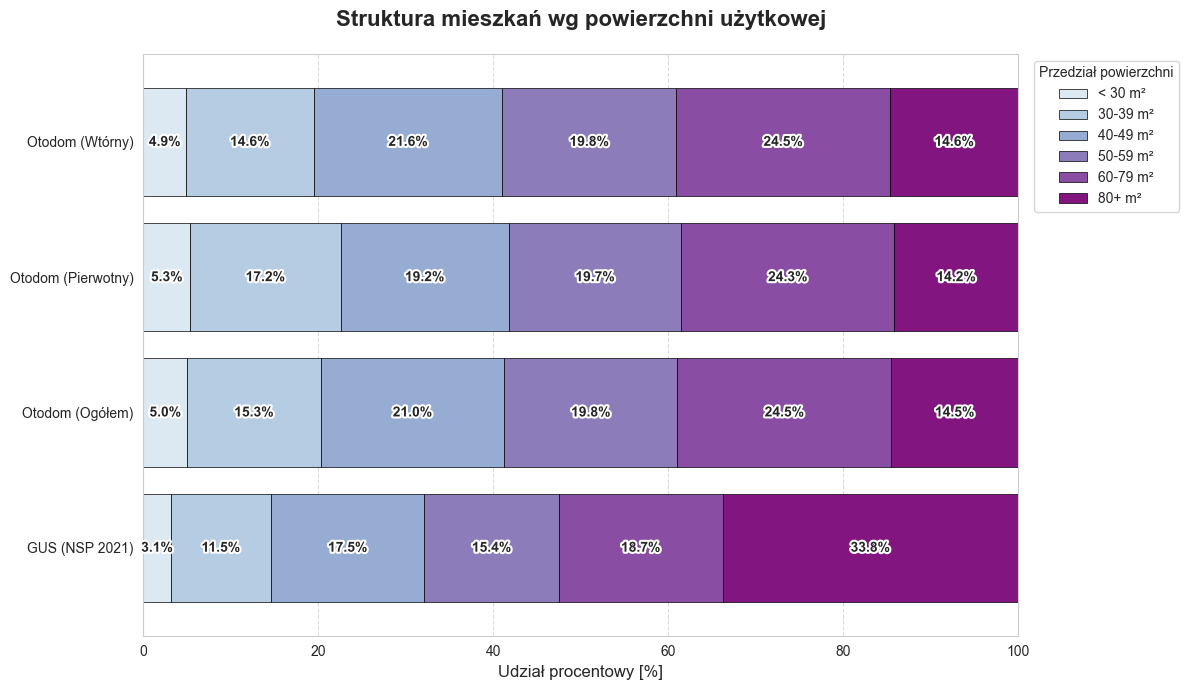

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patheffects as path_effects

sns.set_style("whitegrid")
colors = sns.color_palette("BuPu", 6)

df = pd.read_excel('otodom_scraped_data_ALL.xlsx')

# przygotowanie danych zmapowanie danych
df['RYNEK'] = df['CZY_RYNEK_PIERWOTNY'].map({1: 'Pierwotny', 0: 'Wtorny'})

# stworzenie koszyków -> uwaga -> koszyki dostosowane do danych GUS w celach porównawczych
bins = [0, 30, 40, 50, 60, 80, 1000]
labels = ['< 30 m²', '30-39 m²', '40-49 m²', '50-59 m²', '60-79 m²', '80+ m²']
df['PRZEDZIAL'] = pd.cut(df['POWIERZCHNIA'], bins=bins, labels=labels, right=False)

# przeliczenie danych procentowych
def get_percentages(data):
    return data['PRZEDZIAL'].value_counts(normalize=True).sort_index() * 100

plot_data = pd.DataFrame({
    'Otodom (Wtórny)': get_percentages(df[df['RYNEK'] == 'Wtorny']),
    'Otodom (Pierwotny)': get_percentages(df[df['RYNEK'] == 'Pierwotny']),
    'Otodom (Ogółem)': get_percentages(df),
    'GUS (NSP 2021)': pd.Series([3.1, 11.5, 17.5, 15.4, 18.7, 33.8], index=labels)# dane z GUS
}).T

# wykres
ax = plot_data.plot(
    kind='barh', 
    stacked=True, 
    figsize=(12, 7), 
    color=colors, 
    width=0.8, 
    edgecolor='black', 
    linewidth=0.5
)

# dla czytelności dodany biały efekt wokół cyfr zaimplementowany dzięki Gemini
for p in ax.patches:
    width = p.get_width()
    if width > 1.5:
        t = ax.annotate(
            f'{width:.1f}%', 
            (p.get_x() + width/2, p.get_y() + p.get_height()/2),
            ha='center', va='center', fontsize=10, fontweight='bold'
        )
        t.set_path_effects([path_effects.withStroke(linewidth=3, foreground='white')])

plt.title('Struktura mieszkań wg powierzchni użytkowej', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Udział procentowy [%]', fontsize=12)
plt.xlim(0, 100)
plt.gca().invert_yaxis()
plt.legend(title='Przedział powierzchni', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()

plt.show()

Źródło: Otodom, GUS, opracowanie własne.

Wykres 2. Relacja ceny do powierzchni.

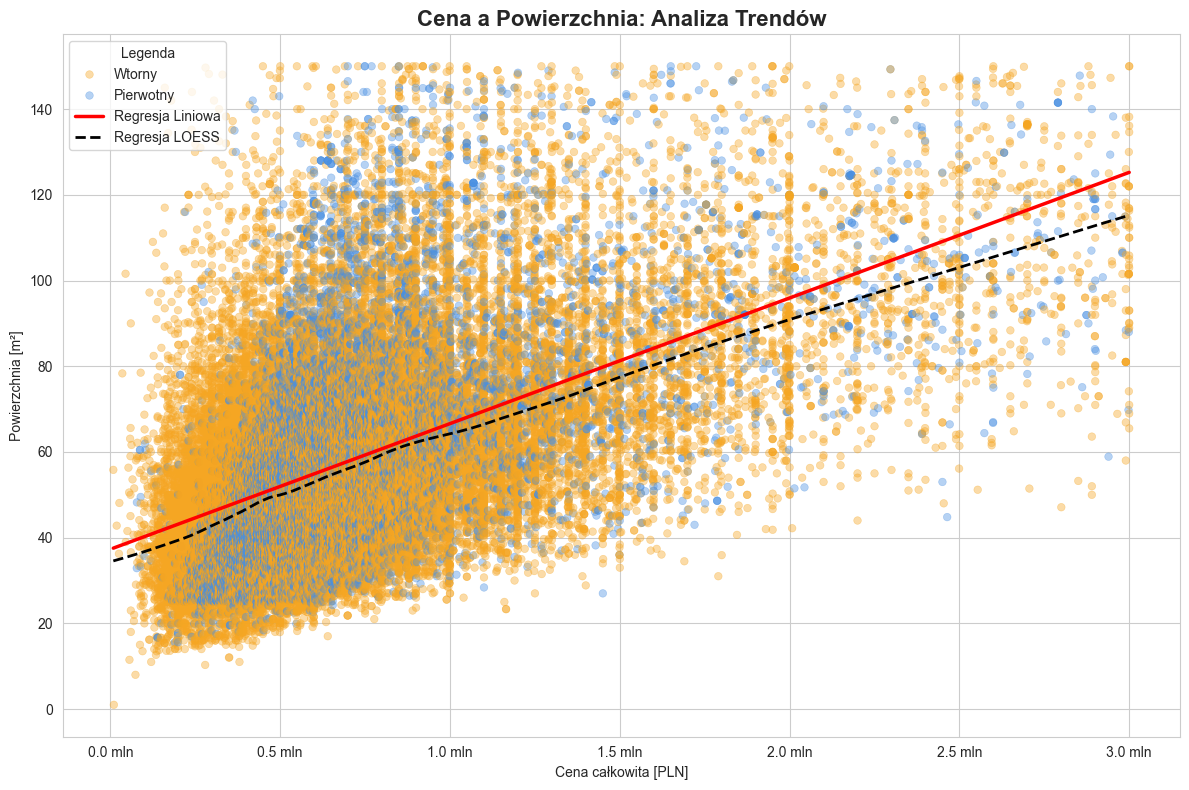



Liczba wszystkich ofert w pliku \ na wykresie wyświetlone: 69636 \ 68391
Liczba punktów odrzuconych: 1245, procent widocznych: 98.21%


In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker
import numpy as np
from statsmodels.nonparametric.smoothers_lowess import lowess

sns.set_style("whitegrid")
df = pd.read_excel('otodom_scraped_data_ALL.xlsx')

# mapowanie
df['RYNEK'] = df['CZY_RYNEK_PIERWOTNY'].map({1: 'Pierwotny', 0: 'Wtorny'})
wszystkie = len(df)
df = df[(df['CENA'] <= 3000000) & (df['POWIERZCHNIA'] <= 150)].sort_values('CENA')# ograniczenie, obejmujące większość przypadków

# 
plt.figure(figsize=(12, 8))
plot = sns.scatterplot(
    data=df, x='CENA', y='POWIERZCHNIA', hue='RYNEK', edgecolor=None,
    palette={"Pierwotny": "#4a90e2", "Wtorny": "#f5a623"}, alpha=0.4, s=30
)

# trendy - zaimplementowane z pomocą Gemini
x, y = df['CENA'], df['POWIERZCHNIA']

# trend liniowy (zaznaczony kolorem czerwonym)
z = np.polyfit(x, y, 1)
p = np.poly1d(z)
plt.plot(x, p(x), color="red", linewidth=2.5, label='Regresja Liniowa')

# trend LOESS (zaznaczony kolorem czarnym)
res = lowess(y, x, frac=0.2)
plt.plot(res[:, 0], res[:, 1], color="black", linestyle="--", linewidth=2, label='Regresja LOESS')

# dodanie opisów
plt.title('Cena a Powierzchnia: Analiza Trendów', fontsize=16, fontweight='bold')
plt.xlabel('Cena całkowita [PLN]')
plt.ylabel('Powierzchnia [m²]')

plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x/1e6:.1f} mln'))# jendostki na mln

plt.legend(title='Legenda', loc='upper left')

plt.tight_layout()
plt.show()

# tutaj info ile zostało wyświetlone!
wyswietlone = len(df)
ukryte = wszystkie - wyswietlone
procent_widocznych = (wyswietlone / wszystkie) * 100

print(f"\n\nLiczba wszystkich ofert w pliku \ na wykresie wyświetlone: {wszystkie} \ {wyswietlone}")
print(f"Liczba punktów odrzuconych: {ukryte}, procent widocznych: {procent_widocznych:.2f}%")


Źródło: Otodom, opracowanie własne. Legenda: linie dopasowania przedstawione odpowiednio dla: wersji liniowej (czerwona linia), LOESS (czarna, przerywana linia).

Wykres 3. Gęstość rozkładu ceny za m2.

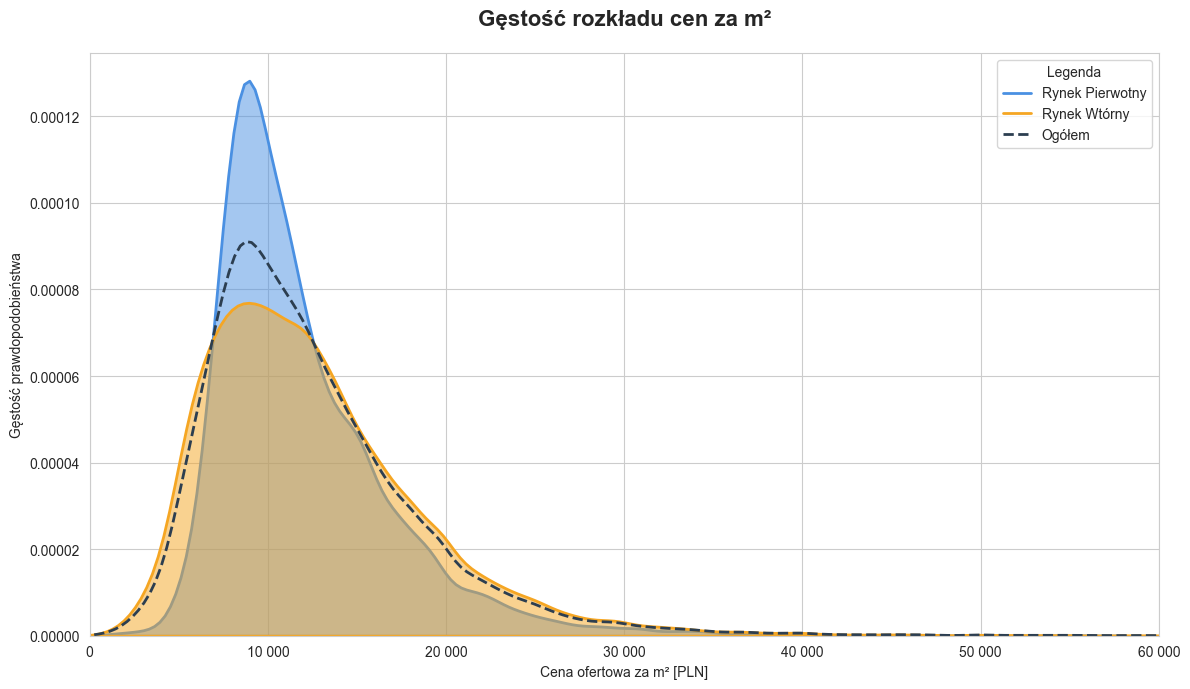



Liczba wszystkich ofert w pliku \ na wykresie wyświetlone: 69636 \ 69569
Liczba punktów odrzuconych: 67, procent widocznych: 99.90%


In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D

sns.set_style("whitegrid")
df = pd.read_excel('otodom_scraped_data_ALL.xlsx')

# mapowanie danych
df['RYNEK'] = df['CZY_RYNEK_PIERWOTNY'].map({1: 'Pierwotny', 0: 'Wtórny'})
df['CENA_M2'] = df['CENA'] / df['POWIERZCHNIA']
wszystkie = len(df)
df = df[(df['CENA_M2'] > 500) & (df['CENA_M2'] < 60000)].copy()# obcięte dla zachowania przejystości wykresu


plt.figure(figsize=(12, 7))

# gęstość dla rynków (zaznaczone kolorami)
sns.kdeplot(
    data=df, x='CENA_M2', hue='RYNEK', 
    palette={"Pierwotny": "#4a90e2", "Wtórny": "#f5a623"},
    fill=True, common_norm=False, alpha=0.5, linewidth=2, legend=False
)

# gęstość ogółem (czarna przerywana linia)
sns.kdeplot(
    data=df, x='CENA_M2', color='#2c3e50', linestyle='--', linewidth=2
)

# format i opis wykresu
plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x:,.0f}'.replace(',', ' ')))
plt.xlim(0, 60000)
plt.title('Gęstość rozkładu cen za m²', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Cena ofertowa za m² [PLN]')
plt.ylabel('Gęstość prawdopodobieństwa')

# legenda
legend_elements = [
    Line2D([0], [0], color="#4a90e2", lw=2, label='Rynek Pierwotny'),
    Line2D([0], [0], color="#f5a623", lw=2, label='Rynek Wtórny'),
    Line2D([0], [0], color='#2c3e50', lw=2, linestyle='--', label='Ogółem')
]
plt.legend(handles=legend_elements, loc='upper right', title='Legenda')

plt.tight_layout()
plt.show()

# tutaj info ile zostało wyświetlone!
wyswietlone = len(df)
ukryte = wszystkie - wyswietlone
procent_widocznych = (wyswietlone / wszystkie) * 100

print(f"\n\nLiczba wszystkich ofert w pliku \ na wykresie wyświetlone: {wszystkie} \ {wyswietlone}")
print(f"Liczba punktów odrzuconych: {ukryte}, procent widocznych: {procent_widocznych:.2f}%")

Źródło: Otodom, opracowanie własne.

Wykres 4. Ceny oferowane za m2 z uwzględnieniem średnich cen NBP (w III kwartale 2025).

/var/folders/f5/37c_2h851jn7l7cgslwg3yxc0000gn/T/ipykernel_35809/3703989797.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  plot = sns.boxplot(


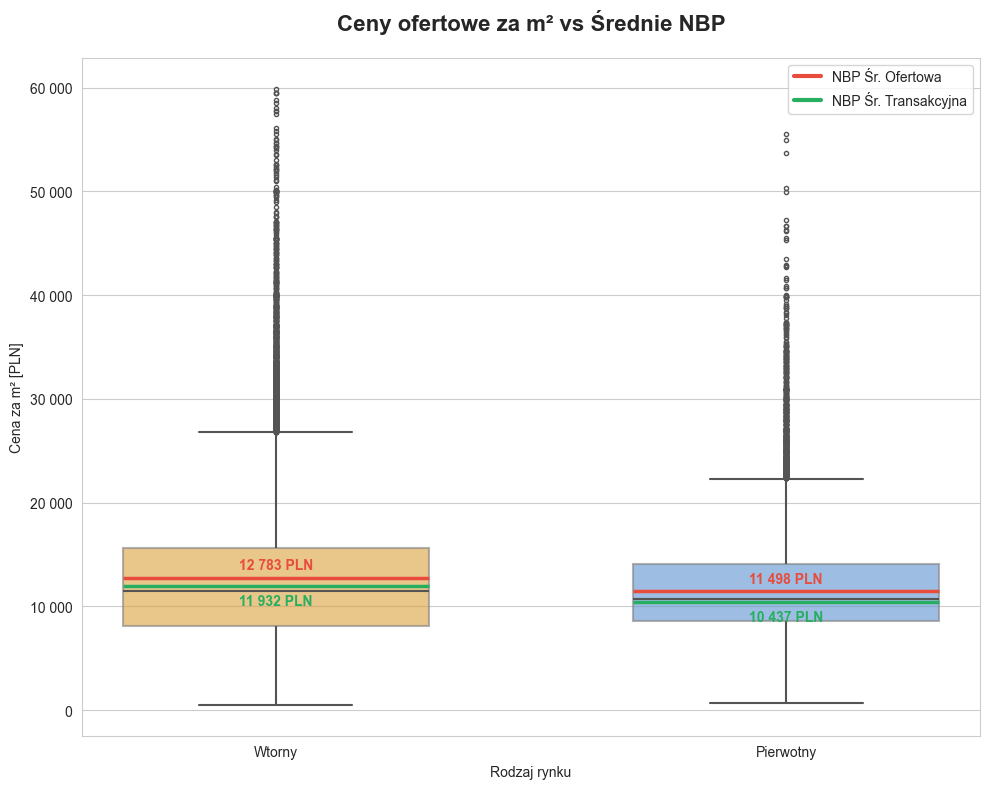



Liczba wszystkich ofert w pliku \ na wykresie wyświetlone: 69636 \ 69569
Liczba punktów odrzuconych: 67, procent widocznych: 99.9038%


In [38]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D

sns.set_style("whitegrid")
Colors = {
    "Pierwotny": "#4a90e2",
    "Wtorny": "#f5a623",
    "NBP_Ofertowa": "#e74c3c",
    "NBP_Transakcyjna": "#27ae60"
}

df = pd.read_excel('otodom_scraped_data_ALL.xlsx')

df['CENA_M2'] = df['CENA'] / df['POWIERZCHNIA']
df['RYNEK'] = df['CZY_RYNEK_PIERWOTNY'].map({1: 'Pierwotny', 0: 'Wtorny'})

wszystkie = len(df)

# Filtracja wartości odstających 500-60000 pln za metr kwadrtowy. Dla czytelności i logiki wykresu
df = df[(df['CENA_M2'] > 500) & (df['CENA_M2'] < 60000)].copy()

# wykres pudełkowy
plt.figure(figsize=(10, 8))
plot = sns.boxplot(
    data=df,
    x='RYNEK',
    y='CENA_M2',
    palette={"Pierwotny": Colors["Pierwotny"], "Wtorny": Colors["Wtorny"]},
    width=0.6,
    showfliers=True,
    fliersize=3,
    linewidth=1.5,
    boxprops=dict(alpha=0.6, edgecolor='grey')
)

# dodanie linii referencyjnych z danych NBP
nbp_data = {
    'Pierwotny': {'Ofertowa': 12783, 'Transakcyjna': 11932},
    'Wtorny': {'Ofertowa': 11498, 'Transakcyjna': 10437}
}

for i, market in enumerate(['Pierwotny', 'Wtorny']):
    vals = nbp_data[market]
    
    # linia ofertowa
    plt.hlines(y=vals['Ofertowa'], xmin=i-0.3, xmax=i+0.3, color=Colors["NBP_Ofertowa"], lw=2.5, zorder=5)
    plt.text(x=i, y=vals['Ofertowa'] + 800, s=f"{vals['Ofertowa']:,} PLN".replace(',', ' '), 
             color=Colors["NBP_Ofertowa"], ha='center', fontweight='bold')

    # linia transakcyjna
    plt.hlines(y=vals['Transakcyjna'], xmin=i-0.3, xmax=i+0.3, color=Colors["NBP_Transakcyjna"], lw=2.5, zorder=5)
    plt.text(x=i, y=vals['Transakcyjna'] - 1800, s=f"{vals['Transakcyjna']:,} PLN".replace(',', ' '), 
             color=Colors["NBP_Transakcyjna"], ha='center', fontweight='bold')

# 
plot.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x:,.0f}'.replace(',', ' ')))
plt.title('Ceny ofertowe za m² vs Średnie NBP', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Cena za m² [PLN]')
plt.xlabel('Rodzaj rynku')

# legenda NBP
legend_elements = [
    Line2D([0], [0], color=Colors["NBP_Ofertowa"], lw=3, label='NBP Śr. Ofertowa'),
    Line2D([0], [0], color=Colors["NBP_Transakcyjna"], lw=3, label='NBP Śr. Transakcyjna')
]
plt.legend(handles=legend_elements, loc='upper right', frameon=True)

plt.tight_layout()
plt.show()


# tutaj info ile zostało wyświetlone!
wyswietlone = len(df)
ukryte = wszystkie - wyswietlone
procent_widocznych = (wyswietlone / wszystkie) * 100

print(f"\n\nLiczba wszystkich ofert w pliku \ na wykresie wyświetlone: {wszystkie} \ {wyswietlone}")
print(f"Liczba punktów odrzuconych: {ukryte}, procent widocznych: {procent_widocznych:.4f}%")

Źródło: Otodom, NBP, opracowanie własne.

##### 2) Rok budowy (wiek zasobu mieszkaniowego)

Badanie roku powstania mieszkań pozwala ujawnić fundamentalne różnice pomiędzy rynkiem wtórnym (oraz ogólnym) Otodom, a danymi GUS (Wykres 5). Na wstępie warto podkreślić, że obserwowany rozkład dla rynku pierwotnego nie stanowi abberacji, lecz jest konsekwencją naturalnej specyfiku tego rynku. Skupia on w sobie mieszkania sprzedawane po raz pierwszy (wcześniej nie użytkowane). Ciężko zatem oczekiwać, że w ramach tej grupy będzie wiele wyników nadal niesprzedanych mieszkań, które wybudowano przed rokiem 2017. Z tego powodu w wypadku analizowanego wykresu skupię się na porównaniu zmiennych GUS do rynku pierwotnego z serwisu Otodom (Wartości dla zagregowanego rynku pierwotnego i wtórnego są silnie zaburzone przez segment rynku pierwotnego).

Główne spostrzeżenia dotyczą niedoreprezentowania starszych zasobów, szczególnie w okresach 1945-1970, 1971-1978, 1979-1988 (odpowiednio -5,6 p.p, -5,8 p.p oraz -6,1 p.p.). Mieszkania wybudowane w tych okresach stanowią istoną część współczesnej bazy mieszkaniowej w Polsce. W szczególności jest to pokłosie projektów budowlanych wykonywanych z prefabrykatow powstające od wczesnych lat 60’, ze sczytowym okresem przypadającym na lata 70’ XX wieku. Należy zwrócić uwagę na fakt, że mniejsze udziały na rynku mieszkań pochodzących z wymienionych orkesów mogą wynikać chociażby z ich dalszej okupacji przez obecnych seniorów. Kolejnym istotnym spostrzeżeniem jest ponad przeciętny udział w rynku wtórnym mieszkań zbudowanych po 2017 roku. Jednakże ich dominacja na rynku (największy udział w rynku wótrnym) może być hipotetycznie wyjaśniony przez większą atrakcyjność mieszkań, oraz zapewnienie lepszego standard (wyższy strop, lepsza termomodernizacja).

Przebadany zbiór danych wykazuje silne zniekształcenie w stronę nowszego budownictwa. Jest to naturalna cecha segmentu rynku mieszkań, która służy głównie do sprzedaży lokali (w tym ważny udział mieszkań deweloperskich oraz lokali inwestytyjnych). Opisywana próba nie jest zatem reprezentatywna dla historycznej struktury miast, ale jest wysoce reprezentatywna dla współczenych preferencji nabywczych konsumentów.

Wykres 5. Strukutra mieszkań według roku budowy.

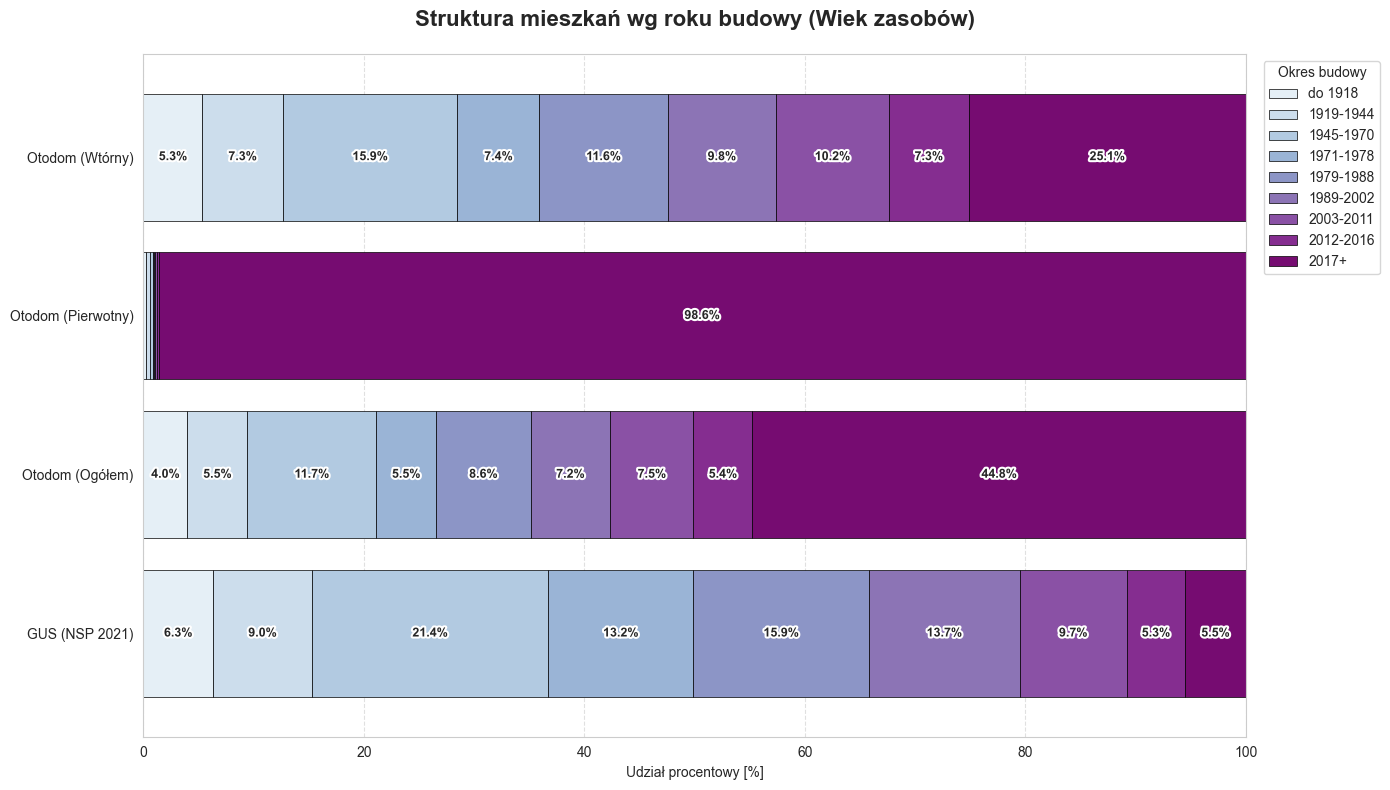



Liczba wszystkich ofert w pliku \ na wykresie wyświetlone: 69636 \ 69541
Liczba punktów odrzuconych: 95, procent widocznych: 99.8636%


In [42]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patheffects as path_effects

sns.set_style("whitegrid")
Colors = {
    "Pierwotny": "#4a90e2",
    "Wtorny": "#f5a623",
    "Ogołem": "#2c3e50"
}

df = pd.read_excel('otodom_scraped_data_ALL.xlsx')

wszytskie = len(df)

# stworzenie filtru dla wartości roku budowy < 1000 i > 2035 - mozna domneimywać, ze są to dane niepoprawnie wprowadzone przez uzytkoniwkow
df = df[(df['Rok_Budowy'] >= 1000) & (df['Rok_Budowy'] <= 2035)]

df['RYNEK'] = df['CZY_RYNEK_PIERWOTNY'].map({1: 'Pierwotny', 0: 'Wtorny'})

# Koszyki dostosowane do przedziałów wykorzystywanych w GUS. Dzięki temu mamy przedziały które mozemy porownywac wartosci.
bins = [0, 1918, 1944, 1970, 1978, 1988, 2002, 2011, 2016, 2035]
labels = [
    'do 1918', '1919-1944', '1945-1970', '1971-1978', '1979-1988', '1989-2002', '2003-2011', '2012-2016', '2017+'
]
df['OKRES'] = pd.cut(df['Rok_Budowy'], bins=bins, labels=labels, right=True)

# Wyznaczanie udziałów
def get_percentages(data):
    return data['OKRES'].value_counts(normalize=True).sort_index() * 100

plot_data = pd.DataFrame({
    'Otodom (Wtórny)': get_percentages(df[df['RYNEK'] == 'Wtorny']),
    'Otodom (Pierwotny)': get_percentages(df[df['RYNEK'] == 'Pierwotny']),
    'Otodom (Ogółem)': get_percentages(df),
    'GUS (NSP 2021)': pd.Series([6.3, 9.0, 21.4, 13.2, 15.9, 13.7, 9.7, 5.3, 5.5], index=labels)
}).T

# wykres
bar_colors = sns.color_palette("BuPu", len(labels))
plot = plot_data.plot(
    kind='barh', stacked=True, figsize=(14, 8), 
    color=bar_colors, width=0.8, edgecolor='black', linewidth=0.5
)

# dodanie etykiet z białą obwalutą
for p in plot.patches:
    width = p.get_width()
    if width > 3.0:
        t = plot.annotate(
            f'{width:.1f}%', 
            (p.get_x() + width/2, p.get_y() + p.get_height()/2),
            ha='center', va='center', fontsize=9, fontweight='bold'
        )
        t.set_path_effects([path_effects.withStroke(linewidth=3, foreground='white')])

# dodanie poozostałych elementów wykresu
plt.title('Struktura mieszkań wg roku budowy (Wiek zasobów)', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Udział procentowy [%]')
plt.xlim(0, 100)
plt.gca().invert_yaxis()

plt.legend(title='Okres budowy', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()

plt.show()

# tutaj info ile zostało wyświetlone!
wyswietlone = len(df)
ukryte = wszystkie - wyswietlone
procent_widocznych = (wyswietlone / wszystkie) * 100

print(f"\n\nLiczba wszystkich ofert w pliku \ na wykresie wyświetlone: {wszystkie} \ {wyswietlone}")
print(f"Liczba punktów odrzuconych: {ukryte}, procent widocznych: {procent_widocznych:.4f}%")

Źródło: Otodom, GUS, opracowanie własne.

##### 3) Liczba pokoi

W ramach zbadnia sturktury liczby pokoi (Wykres 6) można wskazać wyrażne rozróżnienie między rynkiem ofertowym, a ogółem zasobu mieszkaniowego. Struktura zasobów mieszkaniowych zdominowana jest przez mieszkania wielopokojowe (ponad 3 pokoje w mieszkaniu). Równocześnie w segmencie ogólnym Otodom doszło do wyraźniego przeorientowania ilości pomieszczeń w sprzedawanych mieszkaniach. W analizowanym zakresie mieszkania ofeorwane w badanym serwisie posiadają istotnie więcej mieszkań jedno, dwu i trzy pokojowych. A uział pomieszczeń cztero i wiecej pokojowych wyraźnie zmalał. Różnice między segmentem wtórnym i pierwontym Otodom wydają się nieznaczące (jedyna większa różnica to udział mieszkań czteropokojowych, dla której różnica wynosi 6 p.p.).

Główną przycyzną powyższego faktu, może być obserwowana od lat atomizacja społeczna. Ludzie przestają żyć w rodziach wielopokoleniowych, rzadziej zawierają małżeństwa oraz rodzi się mniej dzieci. Są to jedynie przykłądowe powody, dla których na obecnym rynku mieszkaniowym dominują mieszkania dostosowane pod życie par i singli, a nie rodzin wielodzietnych. W aspekcie reprezentatywności danych, raz jeszcze należy stwierdzić, że różnica ta chociaż nie reprezentatywna dla ogółu struktury mieszkań, zdaje się być wysoce reprezentatywna przy uwzględnieniu współczesnych preferencji nabywczych konsumentów (analogicznie jak w przypadku roku budowy).


Wykres 6. Strukutra mieszkań według liczby pokoi.

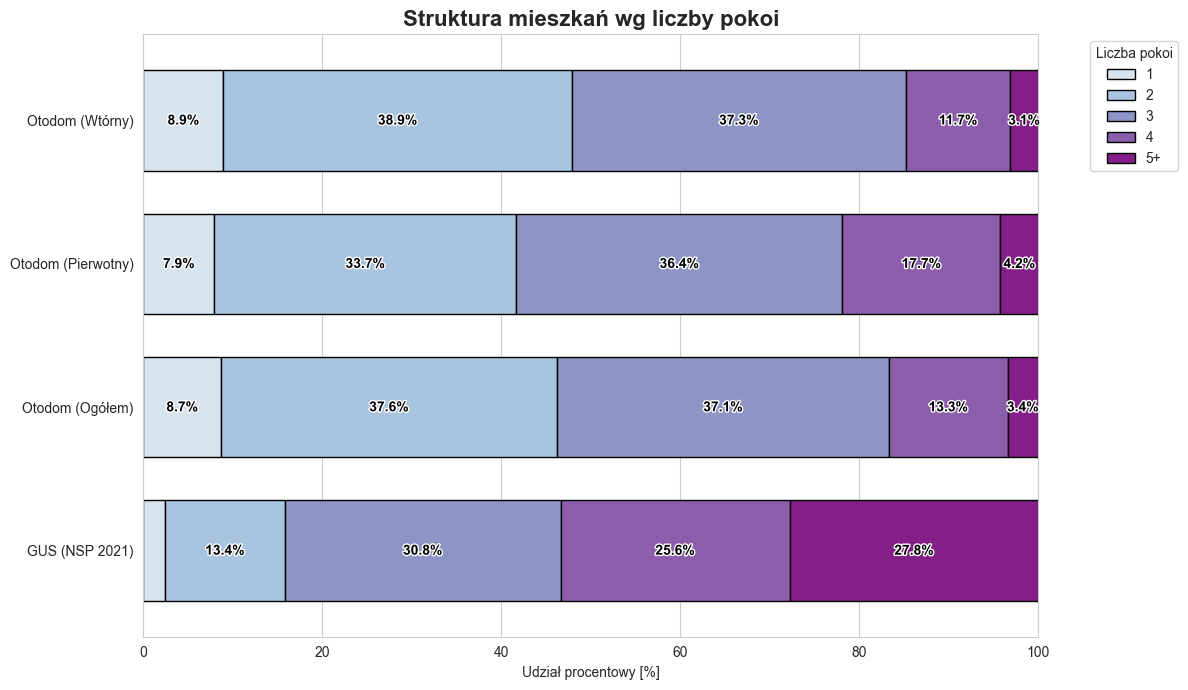

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patheffects as pe

# Ustawienia stylu i ładowanie danych
sns.set_style("whitegrid")
color = sns.color_palette("BuPu", 5)

df = pd.read_excel('otodom_scraped_data_ALL.xlsx')

# mapowanie rynku -> pierwotny/wtórny
df['RYNEK'] = np.where(df['CZY_RYNEK_PIERWOTNY'] == 1, 'Pierwotny', 'Wtorny')

# utworzenie kategorii, dla pokoi +5 w formie zagregowanej
def kat_pokoje(x):
    if pd.isna(x): 
        return "Brak"
    return "5+" if x >= 5 else str(int(x))

df['POKOJE_KAT'] = df['LICZBA_POKOI'].apply(kat_pokoje)

# 
def get_distribution(data):
    return data['POKOJE_KAT'].value_counts(normalize=True).reindex(["1", "2", "3", "4", "5+"], fill_value=0) * 100

df_plot = pd.DataFrame({
    "GUS (NSP 2021)": [2.4, 13.4, 30.8, 25.6, 27.8],
    "Otodom (Ogółem)": get_distribution(df),
    "Otodom (Pierwotny)": get_distribution(df[df['RYNEK'] == 'Pierwotny']),
    "Otodom (Wtórny)": get_distribution(df[df['RYNEK'] == 'Wtorny'])
}).T

# rysowanie wykresu
ax = df_plot.plot(
    kind='barh',
    stacked=True, 
    figsize=(12, 7), 
    color=color, 
    edgecolor='black', 
    width=0.7
)

# legenda - stworzona z pomocą Gemini
for c in ax.containers:
    labels = [f'{v.get_width():.1f}%' if v.get_width() > 3 else '' for v in c]
    texts = ax.bar_label(c, labels=labels, label_type='center', fontsize=10, color='black', fontweight='bold')
    for t in texts:
        t.set_path_effects([pe.withStroke(linewidth=2, foreground='white')])

plt.title('Struktura mieszkań wg liczby pokoi', fontsize=16, fontweight='bold')
plt.xlabel('Udział procentowy [%]')
plt.legend(title='Liczba pokoi', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

Źródło: Otodom, GUS, opracowanie własne.

##### 4) Usytuowanie lokalu (numer piętra), a ceny ofertowe

Przechodząc do charakterystyki dostępności mieszkań względem piętra należy zwrócić uwagę na prawostonną skośność rozkładu liczności (Wykres 7). Najwięcej mieszkań wystawionych na sprzedaż znajduje się na pierwszym piętrze, a liczności wystawionych mieszkań obniżają się wraz ze wzrostem wysokości kondygnacji. Piętra powyżej 10 zostały podane zsumowane w celu poprawy czytelności wykresu. Warto zwrócić uwagę na ciekawą zależność wyceny mieszkania pod względem jakości mieszkania. Mieszkania w suterenie są wyceniane jako najtańsze (mediana 395 tys. PLN), a mieszkania na najwyższych piętrach jako najdroższe (średnio prawie 2,27 krotna różnica median cen). Możemy także zauważyć, że mediany cen mieszkań na piętrach 0-4 są do siebie zbliżone (średnia median wynosi 583 tys. PLN), ale są niższe średnio 1,12 krotnie od mieszkań między 5-10 piętrem (średnia median 652 tys. PLN). Może to wskazywać na jeden z ciekawszych czynników wyceny mieszkania, jakim jest jego fizyczne położenie w bloku. Tak jak mieszkania w suterenie mogą być uznawane za nieatrakcyjne (np. mniejszy dostęp do światła słonecznego), mieszkania na niższych piętrach jako zapewniające mniejszą prywatność, a mieszkania położone na wyższych kondygancjach jako takie, które nie tylko zapewniają wyceniają ładniejszy widok i większą ilość światła, ale także poczucie eksluzywności (tu szczególnie piętra powyżej dziesiatego).

Z uwagi na niedostępności danych referencyjnych dotyczących rozkładu mieszkań według kondygnacji w Narodowym Spisie Powszechnym, w ramach tego obszaru ograniczyłem się wyłącznie do analizy wewnątrzpróbkowej.


Wykres 7. Mediana cen ofertowych, oraz dostępność mieszkań wzgłedem piętra.

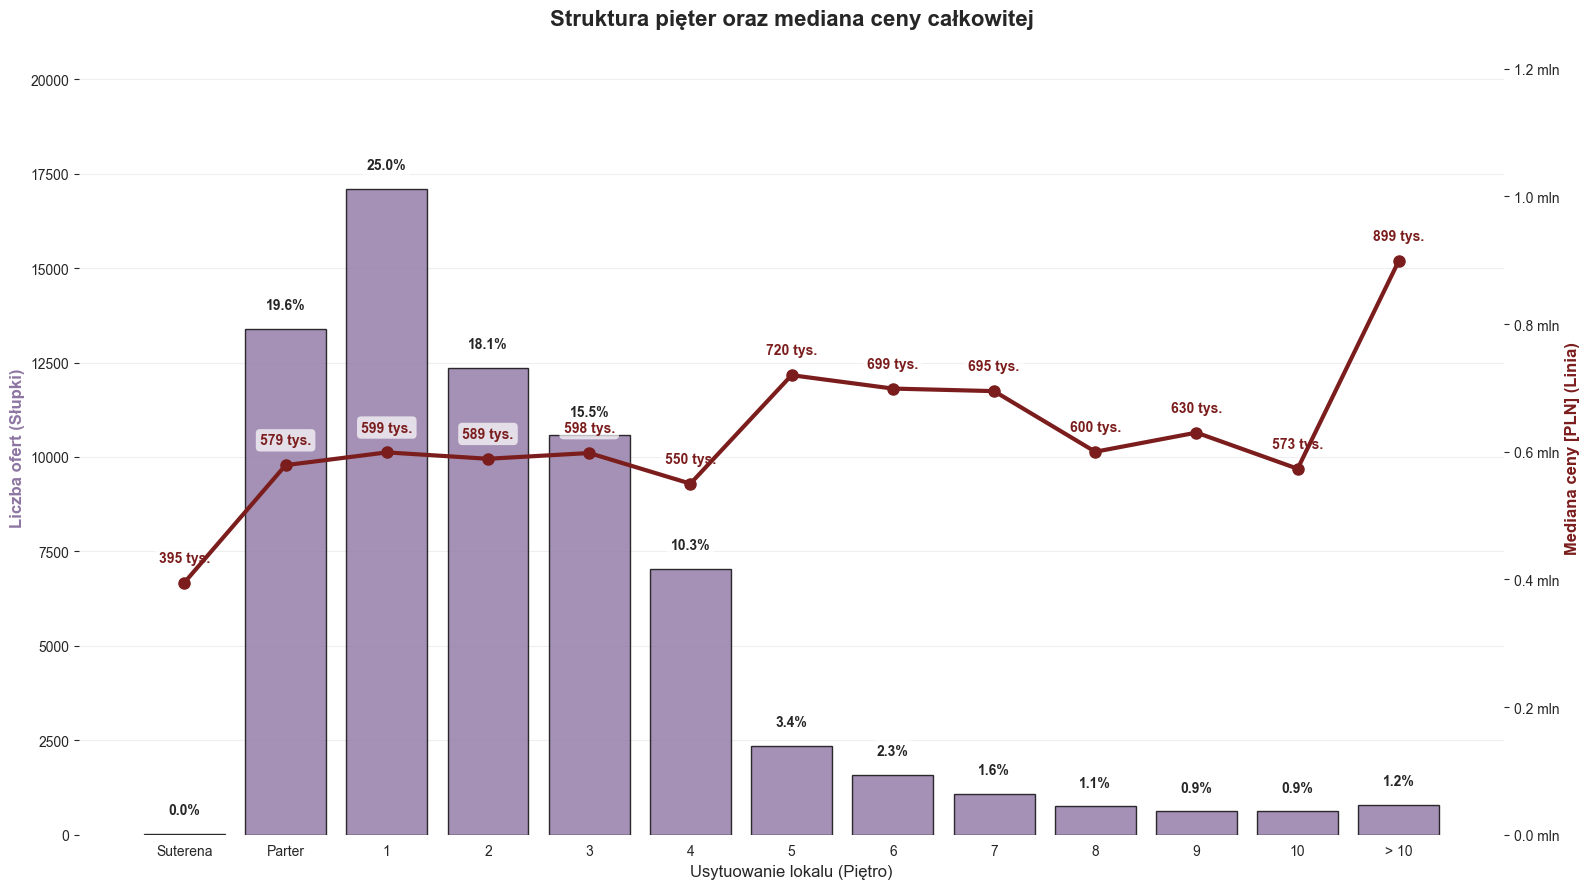



Liczba wszystkich ofert w pliku \ na wykresie wyświetlone: 69636 \ 68288
Liczba punktów odrzuconych: 1348, procent widocznych: 98.0642%


In [46]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

sns.set_style("white")
colors = {
    "Slupki": "#8e76a3",
    "Linia": "#7b1d1d",
    "Tekst_Background": "white"
}

# pobranie danych bez warrtości null
df = pd.read_excel('otodom_scraped_data_ALL.xlsx')
wszystkie = len(df)
df = df.dropna(subset=['NumerPietraPomocniczy', 'CENA'])

# kategoryzacja piętra: suterena / piętra 0-10 / piętra > 10
def kategoryzuj_pietro(val):
    val_str = str(val).lower().strip()
    if 'suterena' in val_str: return 'Suterena'
    if val_str in ['0', '0.0', 'parter']: return 'Parter'
    if '>' in val_str or (val_str.replace('.', '').isdigit() and float(val_str) > 10): 
        return '> 10'
    try:
        num = int(float(val_str))
        if 1 <= num <= 10: return str(num)
    except: pass
    return None

df['PIETRO'] = df['NumerPietraPomocniczy'].apply(kategoryzuj_pietro)
df = df.dropna(subset=['PIETRO'])

# określona kolejność
kolejnosc = ['Suterena', 'Parter'] + [str(i) for i in range(1, 11)] + ['> 10']
df['PIETRO'] = pd.Categorical(df['PIETRO'], categories=kolejnosc, ordered=True)

stats = df.groupby('PIETRO', observed=False)['CENA'].agg(['count', 'median']).reset_index()
total_offers = stats['count'].sum()

# tworzenie wykresu wraz z poprawą siatki (wcześniej błąd podwójnie nałoonych linii pomocniczych)
fig, ax1 = plt.subplots(figsize=(16, 9))
ax2 = ax1.twinx()
ax1.grid(axis='y', linestyle='-', alpha=0.3, zorder=0)

# etykiety danych 
bbox_style = dict(boxstyle='round,pad=0.3', fc=Colors["Tekst_Background"], alpha=0.7, ec='none')

# dodanie słupków danych (liczności ofert w danym przedziale)
bars = ax1.bar(stats['PIETRO'], stats['count'], color=colors["Slupki"], 
                edgecolor='black', alpha=0.8, zorder=3)

for bar in bars:
    height = bar.get_height()
    percentage = (height / total_offers) * 100
    ax1.annotate(f'{percentage:.1f}%', 
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 12), textcoords="offset points",
                 ha='center', va='bottom', fontsize=10, fontweight='bold',
                 bbox=bbox_style)

# dodanie linii danych z NBP
ax2.set_ylim(0, stats['median'].max() * 1.35)# poprawić margines (1.25-1.6)
line = ax2.plot(stats['PIETRO'], stats['median'], color=colors["Linia"], 
                marker='o', linewidth=3, markersize=8, zorder=4)

# wyświetlenie etykiet danych
for i, val in enumerate(stats['median']):
    if not pd.isna(val):
        ax2.annotate(f'{val/1000:.0f} tys.', 
                     xy=(i, val), xytext=(0, 15), textcoords="offset points",
                     ha='center', color=colors["Linia"], fontweight='bold',
                     bbox=bbox_style)

# wyświetlenie opisów
plt.title('Struktura pięter oraz mediana ceny całkowitej', fontsize=16, fontweight='bold', pad=25)
ax1.set_xlabel('Usytuowanie lokalu (Piętro)', fontsize=12)
ax1.set_ylabel('Liczba ofert (Słupki)', color=colors["Slupki"], fontsize=12, fontweight='bold')
ax2.set_ylabel('Mediana ceny [PLN] (Linia)', color=colors["Linia"], fontsize=12, fontweight='bold')

ax2.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x/1e6:.1f} mln'))
ax1.set_ylim(0, stats['count'].max() * 1.2)

sns.despine(left=True, bottom=True, right=True)# usunięcie części obramowań - dla zachowania czytelności
plt.tight_layout()
plt.show()

# tutaj info ile zostało wyświetlone!
wyswietlone = len(df)
ukryte = wszystkie - wyswietlone
procent_widocznych = (wyswietlone / wszystkie) * 100

print(f"\n\nLiczba wszystkich ofert w pliku \ na wykresie wyświetlone: {wszystkie} \ {wyswietlone}")
print(f"Liczba punktów odrzuconych: {ukryte}, procent widocznych: {procent_widocznych:.4f}%")

Źródło: Otodom, opracowanie własne.

#### 4.1.2 Zmienne jakościowe

Druga część analizy skoncentrowała się na cechcach opisowych i standardzie technicznym lokali. Obejmuje ona rodzaj ogrzewania (jako wyznacnik modernizacji), stan technicnzy w relacji do rynku (pierwotny/wtórny), oraz poziom wyposażenia i udogodnień. Zastosowałem w tym miejscu wizualizacje skuione na różnicach strukturalnych oraz przepływach między kategoriami.

##### 1) Rodzaj ogrzewania

Podział na rodzaje ogrzewania mieszkań w obu zbiorach danych nie pozwolił na porównanie ze sobą wszystkich możliwych wartości (różne, czasem niedokładne nazewnictwo możliwych opcji do wyboru w serwisie Otodom, odmienne od przyjętego przez GUS), z tego powodu dokonałem skategoryzowania i oprównania najważniejszego typu ogrzewania jakim okazało się centralne ogrzewanie (Wykres 8). Teoretycznie dotyczy ono sytuacji w której ciepło rozprowadzane po budynku z jednego centralnego źródła. Zatem przyjżenie sie zmiennej opisujacej centralne ogrzewanie jest dobrym indykatorem reprezentowania mieszkań, które znajdują się w dużych skupiskach (bloki w miastach, korzystające z systemu ciepłowniczego) lub średnich skupiskach (bloki posiadające swoją kotłownię - często funkconujące korzystając z sieci gazowej). Pozostałe kategorie takie jak ogrzewanie elektryczne jest częściej wykorzystywane w przypadku niewielkich skupisk mieszkań (np. pojedyńczych bloków z jedynie kilkoma mieszkaniami na terenach wiejskich). Mówimy zatem o dobrym indykatorze zurbanizowania. Wyższy będzie współwystępował z większym wykorzystaniem kategorii opisanych dla dużych skupisk, a niższy dla średnich  i niewielkich skupisk. 
Mimo, że bliżona wartość w obu grupach (87,4% mieszkań dla GUS i 81,8% mieszkań dla Otodom) może sugerować, niewielki problem reprezentatywności danych w serwisie Otodom (w rozumieniu reprezentatywności zurbanizowania). Należy zwrócić uwage na wyznaczenie realnego wskaźnika centralnego ogrzewania dla danych z badanego serwisu internetowego (Wykres 9). Biorąc pod uwagę jedynie wartość “miejskie” relany wskaźnik ogrzewania centralnego (miejskiego) wynosi blisko 59% (28 p.p. różnicy względem danych GUS). Zatem wykorzystując rodzaj ogrzewania jako stowisty indykator dla poziomu reprezentatywności stopnia zurbanizowania, dane seriwsu Otodom nie oddają w pełni krajowej struktury mieszkań.

Wykres 8. Porównanie struktury ogrzewania GUS i Otodom.
Wykres 9. Struktura Centralnego Ogrzewania w ogłoszeniach Otodom.

RAPORT DANYCH OGRZEWANIA (N = 69636)

1) SZCZEGÓŁOWE LICZNOŚCI: OGRZEWANIE
miejskie           41772
gazowe             11712
brak informacji     8844
inne                3654
kotłownia           2112
elektryczne         1376
piece kaflowe        166
Name: count, dtype: int64

2) PO AGREGACJI: KAT_OGRZEWANIE
Centralne      56972
Nieustalone    12664
Name: count, dtype: int64


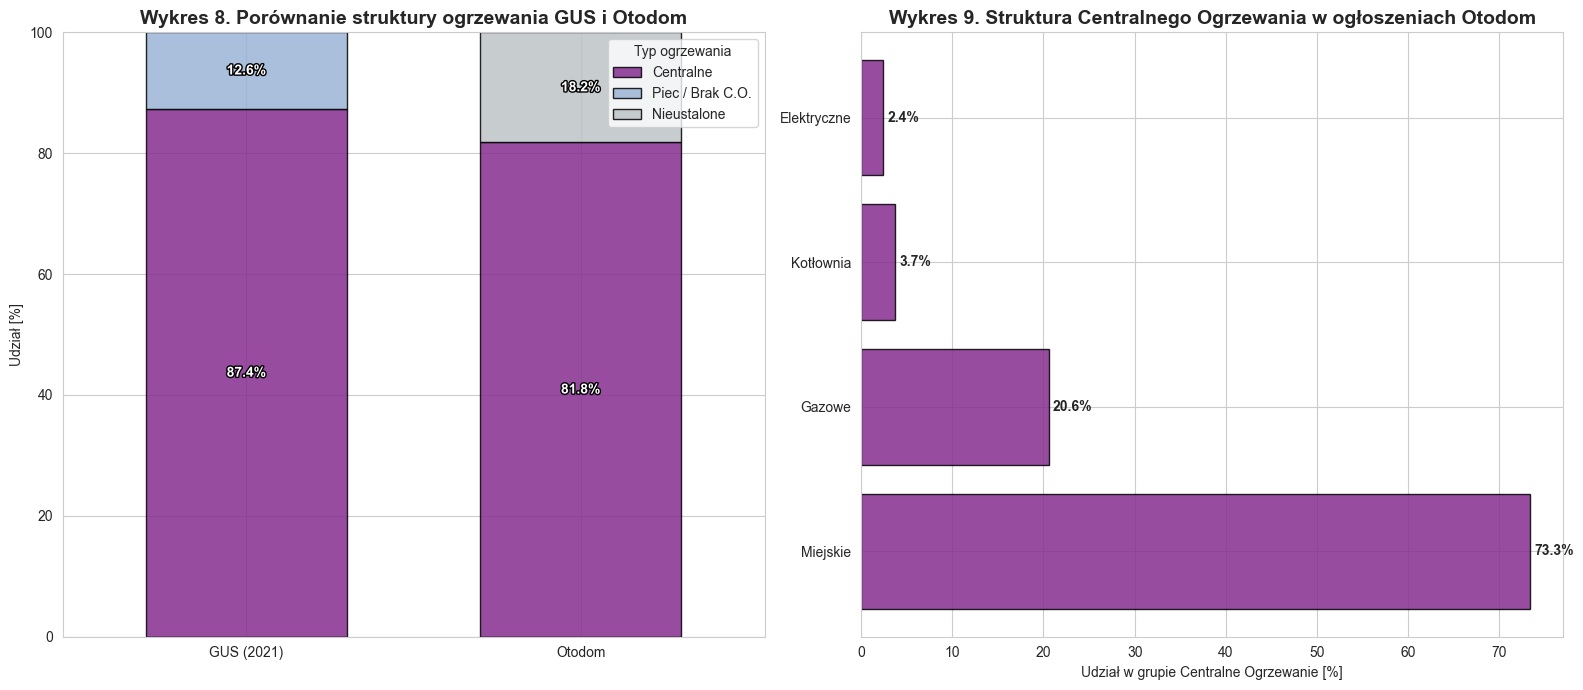

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patheffects as pe

# kolory do wykresu
sns.set_style("whitegrid")
palette_bupu = sns.color_palette("BuPu", 4)

colors_macro = {
    "Centralne": palette_bupu[3],
    "Piec / Brak C.O.": palette_bupu[1],
    "Nieustalone": "#bdc3c7"
}

df = pd.read_excel('otodom_scraped_data_ALL.xlsx')
df = df.rename(columns={'Ogrzewanie': 'OGRZEWANIE'})

# wykorzystany Gemini do poprawnego zaimplementowanego przyjętego podziału, oraz poprawy wygenerowania wykresów.
def kategoryzuj_ogrzewanie(val):
    val = str(val).lower().strip()
    if val in ['miejskie','gazowe','kotłownia','elektryczne']:
        return 'Centralne'
    elif val in ['piec kaflowy']:
        return 'Piec / Brak C.O.'
    return 'Nieustalone' 

df['KAT_OGRZEWANIE'] = df['OGRZEWANIE'].apply(kategoryzuj_ogrzewanie)

# pomocnicze 
print(f"RAPORT DANYCH OGRZEWANIA (N = {len(df)})\n")
print(f"1) SZCZEGÓŁOWE LICZNOŚCI: {df['OGRZEWANIE'].value_counts().head(7)}")
print(f"\n2) PO AGREGACJI: {df['KAT_OGRZEWANIE'].value_counts()}")

otodom_dist = (df['KAT_OGRZEWANIE'].value_counts(normalize=True) * 100).reindex(
    ['Centralne', 'Piec / Brak C.O.', 'Nieustalone'], fill_value=0
)

# w pierwszej kolumnie dane z GUS (wpisane na twardo)
df_macro = pd.DataFrame({
    'Centralne': [87.38, otodom_dist['Centralne']],
    'Piec / Brak C.O.': [12.62, otodom_dist['Piec / Brak C.O.']],
    'Nieustalone': [0.0, otodom_dist['Nieustalone']]
}, index=['GUS (2021)', 'Otodom'])

df_micro = df[df['KAT_OGRZEWANIE'] == 'Centralne']
micro_counts = df_micro['OGRZEWANIE'].value_counts(normalize=True) * 100 if not df_micro.empty else pd.Series(dtype=float)

# stworzenie d∑óch wykresów obok siebie
fig, ax = plt.subplots(1, 2, figsize=(16, 7))

df_macro.plot(
    kind='bar', stacked=True, ax=ax[0],
    color=[colors_macro['Centralne'], colors_macro['Piec / Brak C.O.'], colors_macro['Nieustalone']],
    edgecolor='black', width=0.6, alpha=0.85
)

ax[0].set_title("Wykres 8. Porównanie struktury ogrzewania GUS i Otodom", fontsize=14, fontweight='bold')
ax[0].set_ylabel("Udział [%]")
ax[0].tick_params(axis='x', rotation=0)
ax[0].set_ylim(0, 100)
ax[0].legend(title='Typ ogrzewania', loc='upper right')

for c in ax[0].containers:
    labels = [f'{v.get_height():.1f}%' if v.get_height() > 2 else '' for v in c]
    texts = ax[0].bar_label(c, labels=labels, label_type='center', fontsize=10, color='white', fontweight='bold')
    for text in texts:
        text.set_path_effects([pe.withStroke(linewidth=2, foreground='black')])

if not micro_counts.empty:
    bars = ax[1].barh(
        micro_counts.index.str.capitalize(), 
        micro_counts.values,
        color=colors_macro['Centralne'],
        edgecolor='black', alpha=0.85
    )
    ax[1].set_title("Wykres 9. Struktura Centralnego Ogrzewania w ogłoszeniach Otodom", fontsize=14, fontweight='bold')
    ax[1].set_xlabel("Udział w grupie Centralne Ogrzewanie [%]")
    ax[1].bar_label(bars, fmt='%.1f%%', padding=3, fontsize=10, fontweight='bold')
else:
    ax[1].text(0.5, 0.5, "Brak danych dla grupy Centralne", ha='center')

plt.tight_layout()
#plt.savefig('Wykres_Ogrzewanie.png', dpi=300)
plt.show()

Źródło: Otodom, GUS, opracowanie własne.

##### 2) Stan mieszkania, z podziałem na rynki

Analiza struktury rynku (Wykres 10,11) pozwala na wyraźne wyodrębnienie segmentu pierwotnego oraz wtórnego. Na rynku pierwotnym dominują lokale w stanie do wykończenia (71,7%), przy czym istotny udział mają ogłoszenia bez szczegółowych informacji (18,1%). Rynek wtórny cechuje się znacznie większą precyzją opisu. DOminują w niej mieszkania gotowe do zamieszkania (68,3%), a ofertę uzupełniają lokale do remontu (11,2%), oraz do wykończenia (7,0%). Znikoma liczba ofert z brakiem informacji świadczy o dużej spójności kategoryzacji i rzetelnym odzwierciedleniu rzeczywistości, w której większośc zasobów wtórnych jest gotowa do użytku lub wymaga jedynie odświeżenia.

Wykres 10. Struktura stanu mieszkania w zalezności od rynku.

In [14]:
import pandas as pd
import plotly.graph_objects as go

df = pd.read_excel('otodom_scraped_data_ALL.xlsx')
colors = ['#d1dee8', '#a2a9cc', '#8e5ea2', '#5e3c6f']

# mapowanie rynku -> podział na pierwotny i wtórny
df['RYNEK'] = df['CZY_RYNEK_PIERWOTNY'].map({1: 'Pierwotny', 0: 'Wtórny'})

# grupowanie -> ale z kolumny Stan_wykończenia
mapping_stan = {
    'do remontu': 'Do remontu',
    'do zamieszkania': 'Do zamieszkania',
    'do wykończenia': 'Do wykończenia',
    'brak informacji': 'Brak informacji'
}

# mapowanie
df['STAN_MAP'] = df['Stan_Wykończenia'].map(mapping_stan)

# zliczenie występowania 
plot_data = df.groupby(['RYNEK', 'STAN_MAP']).size().unstack(fill_value=0)

plot_data = plot_data[['Do remontu', 'Do zamieszkania', 'Do wykończenia', 'Brak informacji']]
print(plot_data)# pomocniczo

# obliczenie procentowych udziałów
plot_data_pct = plot_data.div(plot_data.sum(axis=1), axis=0) * 100

fig = go.Figure()

for i, cat in enumerate(plot_data_pct.columns):
    fig.add_trace(go.Bar(
        name=cat,
        x=plot_data_pct.index,
        y=plot_data_pct[cat],
        text=plot_data_pct[cat].apply(lambda x: f'{x:.1f}%' if x > 0 else ''),
        textposition='inside',
        insidetextanchor='middle',
        marker=dict(color=colors[i], line=dict(color='black', width=1)),
        textfont=dict(color='black', family='Arial Black')
    ))

fig.update_layout(
    title=dict(text="<b>Struktura stanu mieszkania w zależności od rynku</b>", x=0.5, font=dict(size=20)),
    yaxis=dict(title="Udział [%]", range=[0, 100], gridcolor='lightgrey'),
    barmode='stack',
    plot_bgcolor='white',
    width=900,
    height=700,
    legend=dict(title="Stan mieszkania", bordercolor="lightgrey", borderwidth=1)
)

fig.show()

STAN_MAP   Do remontu  Do zamieszkania  Do wykończenia  Brak informacji
RYNEK                                                                  
Pierwotny          54             1835           13322             3368
Wtórny           5726            34853            3598             6880


Źródło: Otodom, opracowanie własne.

Wykres 11. Podział ofert z rynku na stan mieszkań.

In [8]:
import pandas as pd
import plotly.graph_objects as go

df = pd.read_excel('otodom_scraped_data_ALL.xlsx')
colors = ["#4a90e2", "#f5a623", "#9b59b6", "#34495e", "#95a5a6", "#bdc3c7"]

# 2mapowanie rynku
df['RYNEK'] = df['CZY_RYNEK_PIERWOTNY'].map({1: 'Pierwotny', 0: 'Wtórny'})

# zmiana brak informacji -> inne (nie usuwam danych)
df['STAN'] = df['Stan_Wykończenia'].replace('Brak informacji', 'Inne')

# przepływy stanów
flows = df.groupby(['RYNEK', 'STAN']).size().reset_index(name='VALUE')

markets = ["Pierwotny", "Wtórny"]
statuses = sorted(df['STAN'].unique().tolist())
all_nodes = markets + statuses

# wyznaczanie liczności
counts = pd.concat([df['RYNEK'].value_counts(), df['STAN'].value_counts()])
node_labels = [f"{node}<br>(N={counts.get(node, 0)})" for node in all_nodes]

# indeksy dla plotly
label_map = {name: i for i, name in enumerate(all_nodes)}
source_indices = flows['RYNEK'].map(label_map)
target_indices = flows['STAN'].map(label_map)

# wykres zaimplementowany z pomocą Gemini
fig = go.Figure(data=[go.Sankey(
    valueformat = ".0f",
    valuesuffix = " ofert",
    node = dict(
        pad = 20, thickness = 30,
        line = dict(color = "black", width = 0.5),
        label = node_labels,
        color = colors[:len(all_nodes)]
    ),
    link = dict(
        source = source_indices,
        target = target_indices,
        value = flows['VALUE'],
        color = "rgba(189, 195, 199, 0.4)",
        hovertemplate='Z: %{source.label}<br>Do: %{target.label}<br>Liczba: %{value} ofert<extra></extra>'
    )
)])

fig.update_layout(
    title_text="<b>Przepływ ofert: Rynek -> Stan Mieszkania</b>",
    width=1000, height=600, font_family="Arial"
)

fig.show()

Źródło: Otodom, opracowanie własne.

##### 3) Udogodnienia i wyposażenie

W ramach ostatniego badanego zagadnienia przedstawiam udogodnienia i wyposażenie, które wystawiający mieszkania w serwisie Otodom wymienili w swoich ofertach (Wykres 12, 13). Większość ofert zawierała 2 udogodnienia, a jedynie w przypadku blisko 35% ofert zawierały one więcej niż 3 udogodnienia (udogodnienia i wyposażenie traktuje się jako tożsame, tj. w skład zmiennej wchodzą dane z wymienionych w ofertach udogodnień oraz czy posiadany balkon/taras/ogródek, czy posiada garaz, a takze winde). Jednak niezwykle ciekawszy okazał się wynik zaprezentowany na Wykresie 13. W ramach niego przedstawiłem konkretne udogodnienia oraz odsetek częstości wystąpień w ofertach z podziałem na rynek pierwotny i wtórny. Warto zwrócić uwagę na powstały podział. Dla rynku pierwotnego znacznie częściej powtarzającym się udogodnieniem był: balkon/taras/ogród, garaż/m.postojowe oraz winda. A dla rynku wtórnego międzyinnymi: meble, lodówka, piekarnik, kuchenka, zmywarka, pralka, oraz pozostałe (kategoria udogodnień powtarzająca się mniej niż w 3% przypadków). Ewidentną cechą wspólną mieszkań wtórnych, które przez wystawiajacych mieszkania widziana jest jako atut jest mieszkanie umeblowame i posiadajace AGD. Równocześnie mieszkania na rynku pierotnym częściej dotyczą elementów infrastrukturalnych. Obserwowana dychotomia odzwierciedla naturalną specyfikę obu sektorów. Rynek pierwotny sprzedaje potencjał i udogodnienia architektoniczne dostosowane pod współczenych konsumentów, natomiast rynek wtórny oferuję wygodę w postaci mieszkań umeblowanych i ze sprzętem AGD.

Wykres 12. Histogram reprezentujący ile elementów wyposaenia posiada mieszkanie.

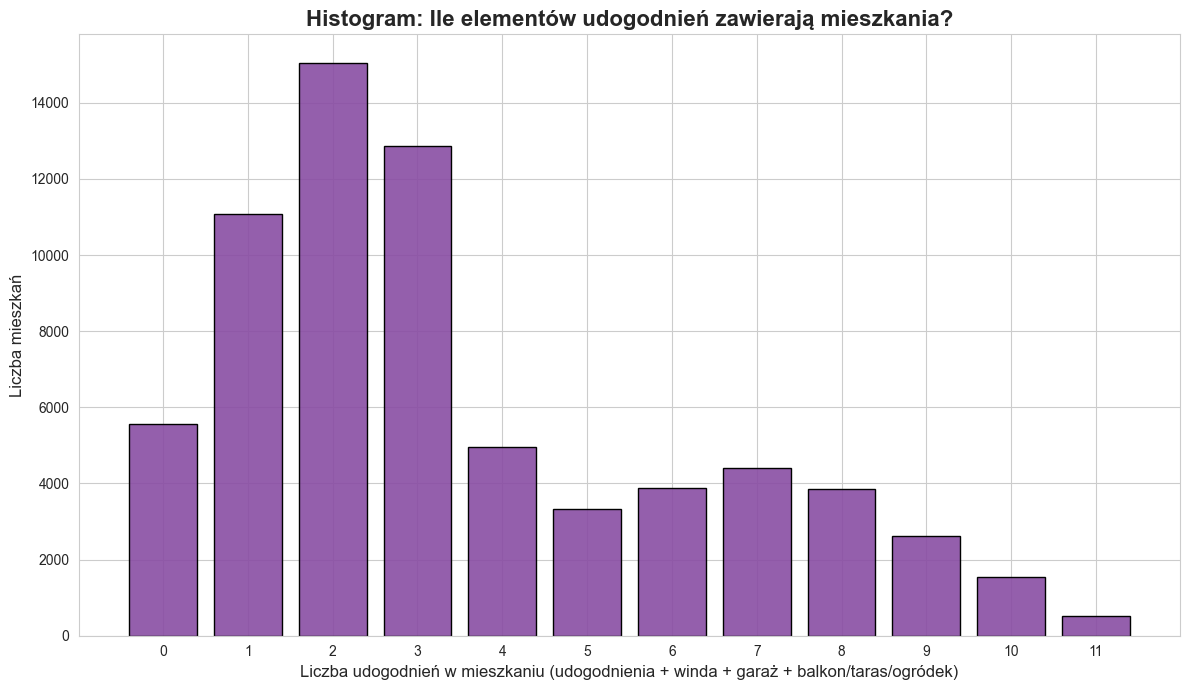

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

file_path = 'otodom_scraped_data_ALL.xlsx'
df = pd.read_excel(file_path)

# kolory
sns.set_style("whitegrid")
color = sns.color_palette("BuPu", 6)[4] 

# kolumna z sumą udogodnień
df['SUMA_UDOGODNIEN'] = (
    df['ILE_WYPOSAZENIA'] + 
    df['CZY_WINDA'] + 
    df['CZY_TARAS_LUB_BALKON_LUB_OGRODEK'] + 
    df['CZY_GARAZ']
)

# rysowanie wykresu
plt.figure(figsize=(12, 7))

sns.histplot(
    data=df, x='SUMA_UDOGODNIEN', discrete=True,
    color=color, edgecolor='black', alpha=0.9, shrink=0.8
)

plt.title('Histogram: Ile elementów udogodnień zawierają mieszkania?', fontsize=16, fontweight='bold')
plt.xlabel('Liczba udogodnień w mieszkaniu (udogodnienia + winda + garaż + balkon/taras/ogródek)', fontsize=12)
plt.ylabel('Liczba mieszkań', fontsize=12)

max_wyposazenia = int(df['SUMA_UDOGODNIEN'].max())
plt.xticks(range(0, max_wyposazenia + 1))

plt.tight_layout()
plt.show()

Źródło: Otodom, opracowanie własne.

Wykres 13. Dostępne udogodnienia w podziale na mieszkania.

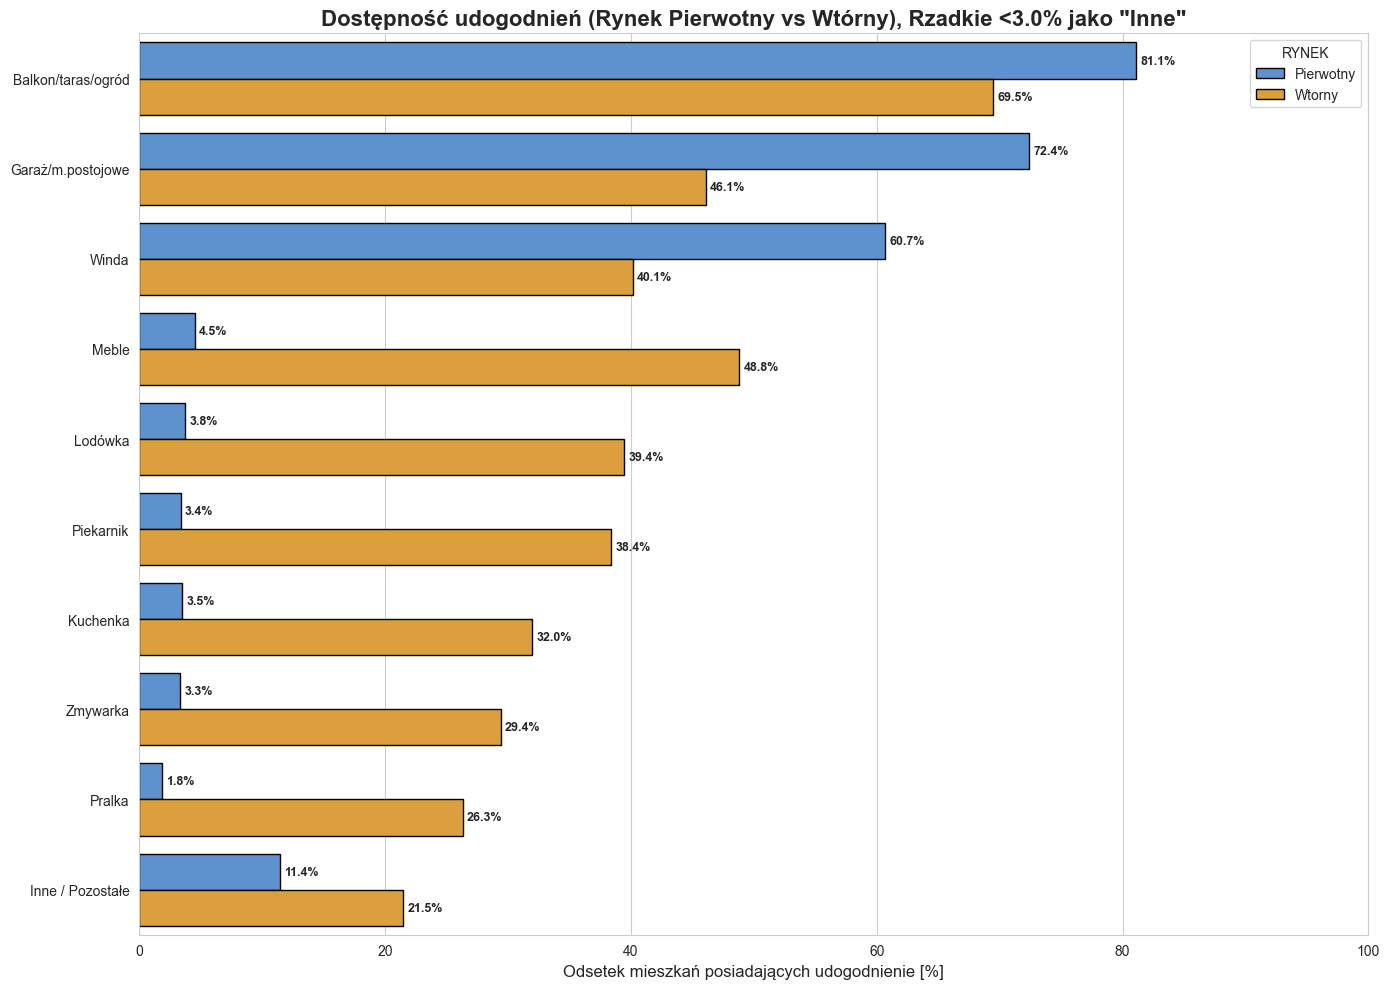

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel('otodom_scraped_data_ALL.xlsx')

sns.set_style("whitegrid")
colors = {"Pierwotny": "#4a90e2", "Wtorny": "#f5a623"}

# utworzonny skrypt z pomocą Gemini do zaimplementowania rozdzielenia i zliczenia wyrazów
df['RYNEK'] = np.where(df['CZY_RYNEK_PIERWOTNY'] == 1, 'Pierwotny', 'Wtorny')

df['Winda'] = np.where(df['CZY_WINDA'] == 1, 'Winda', None)
df['Balkon/Ogród'] = np.where(df['CZY_TARAS_LUB_BALKON_LUB_OGRODEK'] == 1, 'Balkon/Taras/Ogród', None)
df['Garaż'] = np.where(df['CZY_GARAZ'] == 1, 'Garaż/M.Postojowe', None)

# rozbicie na oddzielene wiersze
df['ALL_STR'] = df[['Wyposażenie', 'Winda', 'Balkon/Ogród', 'Garaż']].apply(lambda x: ','.join(x.dropna().astype(str)), axis=1)
df_exp = df[['RYNEK', 'ALL_STR']].assign(UDOGODNIENIE=df['ALL_STR'].str.split(',')).explode('UDOGODNIENIE')
df_exp['UDOGODNIENIE'] = df_exp['UDOGODNIENIE'].str.strip().str.capitalize()
df_exp = df_exp[df_exp['UDOGODNIENIE'].str.len() > 1]

# zliczenie i grupowanie wartości + obliczenie % wartości
totals = df['RYNEK'].value_counts()
counts = df_exp.groupby(['RYNEK', 'UDOGODNIENIE']).size().reset_index(name='LICZBA')
counts['PROCENT'] = counts.apply(lambda r: (r['LICZBA'] / totals[r['RYNEK']]) * 100, axis=1)

global_pct = df_exp['UDOGODNIENIE'].value_counts(normalize=True) * 100
rare = global_pct[global_pct < 3.0].index
counts['UDOGODNIENIE'] = counts['UDOGODNIENIE'].apply(lambda x: 'Inne / Pozostałe' if x in rare else x)

counts = counts.groupby(['RYNEK', 'UDOGODNIENIE'])['PROCENT'].sum().reset_index()

# sortowanie
top_order = counts.groupby('UDOGODNIENIE')['PROCENT'].sum().sort_values(ascending=False).index.tolist()
if 'Inne / Pozostałe' in top_order:
    top_order.remove('Inne / Pozostałe')
    top_order.append('Inne / Pozostałe')

# tworzenie wykresu
plt.figure(figsize=(14, 10))

ax = sns.barplot(
    data=counts, x='PROCENT', y='UDOGODNIENIE', hue='RYNEK',
    order=top_order, palette=colors, edgecolor='black'
)

plt.title('Dostępność udogodnień (Rynek Pierwotny vs Wtórny), Rzadkie <3.0% jako "Inne"', fontsize=16, fontweight='bold')
plt.xlabel('Odsetek mieszkań posiadających udogodnienie [%]', fontsize=12)
plt.ylabel('')
plt.xlim(0, 100)

for c in ax.containers:
    labels = [f'{v.get_width():.1f}%' if v.get_width() > 1 else '' for v in c]
    ax.bar_label(c, labels=labels, padding=3, fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

Źródło: Otodom, opracowanie własne.

### 4.2 Parametry cenowe, a typ oferenta - odpowiedź na postawioną hipotezę poszerzającą zakres analizy danych

W poniższej części przestawię odpowiedzi na zadaną hipotezę badawczą, przy założeniu poziomu istotności równego 5%.

**H1)**

Hipoteza Zerowa: *Ogłoszenia prywatne nie charakteryzują sie istotnie niższą ceną oferowaną niż ogłoszenia agencyjne*.

Hipoteza Alternatywna: *Ogłoszenia prywatne charakteryzują się istotnie niższą ceną oferowaną niż ogłoszenia agencyjne*.


W celu weryfikacji hipotezy H1 przeprowadziłem nieparametryczny test U Manna-Whitney’a dla dwóch prób niezależnych. Wybór testu podyktowany był rozkładem cen mieszkań, który wykazywał silną prawostronną skośność oraz obecnośc obserwacji skrajnych. Narusza to założenie o normalności rozkładu wymagane przez testy parametryczne. Test przeprowadziłem w wersji jednostronnej, zakładając, że ceny w ogłoszeniach prywatnych są niższe niż w ogłoszeniach wystawianych przez biura nieruchomości. Wynik testu (Rysunek 1) nie wykazał isotnej statystycznie różnicy pomiędzy analizowanymi grupami (p-value > 0.05). Zatem brak podstaw do odrzucenia hipotezy zerowej. Hipoteza Alternatywna nie została powierdzona. Ceny mieszkań w ogłoszeniach prywatnych nie są istotnie niższe niż w ogłoszeniach agencyjnych.

Rysunek 1. 

In [6]:
import pandas as pd
from scipy.stats import mannwhitneyu

# wczytanie danych
df = pd.read_excel('otodom_scraped_data_ALL.xlsx')

# wyekstraktowanie dwoch grup cen: 1. ogłoszenia prywatne (OGLOSZENIE_PRYWATNE==1) 2. ogłoszenia agencyjne (OGLOSZENIE_PRYWATNE==0)
ceny_priv = df[df['OGLOSZENIE_PRYWATNE'] == 1]['CENA']
ceny_agen = df[df['OGLOSZENIE_PRYWATNE'] == 0]['CENA']

# czy popranwie pobrane
print(ceny_priv.head(10))
print(ceny_agen.head(10))
# statystyki
print(f"\n\nLiczba ofert prywatnych: {ceny_priv.count()}")
print(f"Liczba ofert agencyjnych: {ceny_agen.count()}")
print(f"\n\nStatystyki ofert prywatnych: {ceny_priv.describe()}")
print(f"\n\nStatystyki ofert agencyjnych: {ceny_agen.describe()}")

# test statystyczny
stat_u, p_val = mannwhitneyu(ceny_priv, ceny_agen, alternative='less')# less -> parametr testujący hipotezę gdzie wartości ceny prywatne < ceny agencyjne

alpha = 0.05

print("\n\nWeryfikacja hipotezy H1:")
print(f"Statystyka U: {stat_u}\nP-value: {p_val:.10f}\n")

if p_val < alpha:
    #odrzucamy H0
    print("Wniosek: Odrzucamy H0 na rzecz Hipotezy Alternatywnej.")
else:
    #brak podstaw do odrzucenia H0
    print("Wniosek: Brak podstaw do odrzucenia H0.")






60586     929000.0
60587    1990000.0
60588     580000.0
60589     395000.0
60590     479000.0
60591    1750000.0
60592     450000.0
60593     437000.0
60594     217000.0
60595     749000.0
Name: CENA, dtype: float64
0     700000.0
1     969000.0
2     420000.0
3     999900.0
4     327573.0
5     375000.0
6     380000.0
7    2599999.0
8     835000.0
9     799000.0
Name: CENA, dtype: float64


Liczba ofert prywatnych: 9050
Liczba ofert agencyjnych: 60586


Statystyki ofert prywatnych: count    9.050000e+03
mean     6.933641e+05
std      4.425808e+05
min      8.500000e+03
25%      4.312222e+05
50%      5.990000e+05
75%      8.100000e+05
max      1.111111e+07
Name: CENA, dtype: float64


Statystyki ofert agencyjnych: count    6.058600e+04
mean     7.432499e+05
std      6.834742e+05
min      2.632675e+04
25%      4.300000e+05
50%      5.980000e+05
75%      8.250000e+05
max      2.500000e+07
Name: CENA, dtype: float64


Weryfikacja hipotezy H1:
Statystyka U: 273439665.5
P-value: 0.344892365

Źródło: Otodom, opracowanie własne.

## Podsumowanie

Przeprowadzona analiza porównawcza pozwala na jednoznaczną odpowiedź na pierwsze pytanie badawcze **(P1)**. Zgromadzony zbiór danych ofertowych nie jest reprezentatywny dla ogółu zasobów mieszkaniowych w Polsce, lecz stanowi dobre odzwierciedlenie aktywnego rynku obrotu nieruchomościami. Za postawioną oceną przemawiają zaobserowane rozbieżności, między innymi nadreprezentacja mieszkań wybudowanych po 2017 roku, dominacja lokali o małej liczbie pokoi, a także przedstawiona struktura ogrzewania. Można równocześnie stwierdzić, że serwis Otodom precyzyjnie obrazuje współczesne preferencje nabywcze oraz standard deweloperski, co czyni go wartościowym źródłem do analizy bierzących trendów rynku mieszkaniowego, mimo braku całkowitej zgodności z krajową strukturą mieszkaniową.

Odnosząc uzyskany wynik weryfikacji hipotezy **(H1)** do postawionego pytania badawczego **(P2)**, należy stwierdzić, że typ oferenta nie jest istotnym czynnikiem róźnicującym parametry cenowe ofert. Sugeruje to, że mechanizmy wyceny stosowane przez właścicieli bezpośrednio sprzedające mieszkania są zbierzne z wycenami profesjonalnych pośredników zatrudnionych w biurach nieruchomości. Podsumowując, w przebadanym aspekcie, pochodzenie oferty nie determinuje atrakcyjności cenowej ogłoszenia dla potencjalnego nabywcy.

## Bibliografia
1. Otodom. *Oferty sprzedaży mieszkań w Polsce: dane surowe pozyskane metodą web scrapingu.* Pobrano 10-15 grudnia 2025 z: [otodom.pl](https://otodom.pl) 
2. Główny Urząd Statystyczny. (2024). *Warunki mieszkaniowe w Polsce w świetle wyników Narodowego Spisu Powszechnego Ludności i Mieszkań 2021.* Dostępna na [stat.gov.pl](https://stat.gov.pl/spisy-powszechne/nsp-2021/nsp-2021-wyniki-ostateczne/warunki-mieszkaniowe-w-polsce-w-swietle-wynikow-narodowego-spisu-powszechnego-ludnosci-i-mieszkan-2021,5,2.html)
3. Narodowy Bank Polski. (2025). *Informacja o cenach mieszkań i sytuacji na rynku nieruchomości mieszkaniowym i komercyjnym w Polsce w III kwartale 2025 r.* Dostępne na [nbp.pl](https://nbp.pl/publikacje/cykliczne-materialy-analityczne-nbp/rynek-nieruchomosci/informacja-kwartalna/)